# Santali baseline v2: original vocabulary + LoRA, trained with the same loop as the extended model

**Why this notebook exists.** The first baseline was trained for 7 epochs (interrupted) in an unscaled fp16 loop, while the extended model used autocast + GradScaler for 10 epochs. This notebook retrains the **original-vocabulary LoRA baseline for the full 10 epochs, using the extended run's training procedure**, then evaluates it under one fixed pipeline and compares it with the old baseline and the extended results.

**What stays identical to the earlier runs:** model `ai4bharat/indictrans2-indic-indic-1B`, English to Santali, same saved splits, `IndicProcessor` source preprocessing, LoRA r=16 / alpha=32 / dropout 0.05 on `q_proj` and `v_proj`, batch 4 x accumulation 4, learning rate 1e-4, weight decay 0.01, 3% warmup then linear decay, gradient clipping at 1.0, early stopping (patience 2, minimum delta 0.001), seed 42.

**What changes relative to the old baseline:** fp16 autocast + GradScaler with non-finite-gradient skipping, 10 planned epochs, and a reproducible per-epoch data order (generator seeded with 42 + epoch).

## Inputs and settings required before running
| Item | Required | Notes |
|---|---|---|
| Notebook setting: **Internet = On** | yes | pip install and the Hugging Face model download |
| Notebook setting: **Accelerator = GPU T4** | yes | one GPU is used |
| Kaggle secret **`HF_TOKEN`** (Add-ons > Secrets) | yes | your Hugging Face token |
| Dataset **Common Tribal Preprocessing** (contains `splits/santali_*.parquet`) | yes | already attached in your earlier notebooks |
| Dataset **santali_exp** (old baseline folder + `extended_model_test_predictions.csv`) | for the comparison sections | needed for old-baseline adapter and extended predictions |
| `candidate_lists_by_threshold.json` (from the audit notebook) | optional | only for the added-word subset analysis and spacing estimate; add it to a dataset |
| Output of an earlier run of this notebook (folder `baseline_v2_scaled`) | only when resuming | attach as a dataset; training resumes automatically |

**Run order:** run Section 1 cell 1 (install), then **restart the session** (Run menu > Restart session), then run everything from Section 1 cell 2 onward. Do not rerun the install cell after the restart.

**Time:** about 12 to 15 minutes per epoch, so roughly 2 to 2.5 hours for 10 epochs, plus about 15 to 20 minutes for evaluation.

## Section 1. Environment
Install the same pinned packages as the earlier notebooks. After the install cell finishes, restart the session before continuing.

In [ ]:
# Section 1.1: install pinned dependencies (run ONCE, then restart the session)
%pip install -q --no-cache-dir \
    "transformers==4.46.3" \
    "tokenizers==0.20.3" \
    "IndicTransToolkit==1.1.1" \
    peft accelerate sacrebleu sentencepiece kagglehub

In [1]:
# Section 1.2: verify packages and GPU (run after the restart)
import sys
import importlib.metadata as metadata
import torch

print("=== Package versions ===")
for package in ["transformers", "tokenizers", "IndicTransToolkit", "torch", "peft", "accelerate", "sacrebleu", "sentencepiece"]:
    try:
        print(f"{package:20s}: {metadata.version(package)}")
    except metadata.PackageNotFoundError:
        print(f"{package:20s}: NOT INSTALLED")

print("\nPython:", sys.version.split()[0])
print("CUDA available:", torch.cuda.is_available())
assert torch.cuda.is_available(), "No GPU. Set Accelerator to GPU T4 and restart the session."
print("GPU:", torch.cuda.get_device_name(0))
print("GPU memory (GiB): %.1f" % (torch.cuda.get_device_properties(0).total_memory / 1024**3))

import transformers
assert transformers.__version__ == "4.46.3", "transformers is not 4.46.3: rerun the install cell and restart the session."

=== Package versions ===
transformers        : 4.46.3
tokenizers          : 0.20.3
IndicTransToolkit   : 1.1.1
torch               : 2.11.0+cu128
peft                : 0.20.0
accelerate          : 1.14.0
sacrebleu           : 2.6.0
sentencepiece       : 0.2.2

Python: 3.13.15
CUDA available: True
GPU: Tesla T4
GPU memory (GiB): 14.6


## Section 2. Authentication and configuration
All training settings are defined here, in one place. `MAX_EPOCHS_THIS_SESSION` lets you stop cleanly after a number of epochs and resume later from the saved checkpoint.

In [2]:
# Section 2.1: imports, Hugging Face login, configuration
import gc, glob, json, math, os, random, re, shutil, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader
from torch.optim.lr_scheduler import LambdaLR
from kaggle_secrets import UserSecretsClient
from huggingface_hub import login

warnings.filterwarnings("ignore")

hf_token = UserSecretsClient().get_secret("HF_TOKEN")
login(token=hf_token)
print("Hugging Face authentication complete.")

DEVICE = torch.device("cuda")
MODEL_ID = "ai4bharat/indictrans2-indic-indic-1B"
SRC_LANG, TGT_LANG = "eng_Latn", "sat_Olck"

# Training configuration (identical to the earlier baseline and extended runs)
SEED = 42
BATCH_SIZE, GRAD_ACCUM = 4, 4
NUM_EPOCHS = 10
LEARNING_RATE, WEIGHT_DECAY = 1e-4, 0.01
WARMUP_RATIO, MAX_GRAD_NORM = 0.03, 1.0
PATIENCE, MIN_DELTA = 2, 0.001
MAX_LEN = 256

# Stop cleanly after this many epochs in one session (set to NUM_EPOCHS to run everything)
MAX_EPOCHS_THIS_SESSION = NUM_EPOCHS

RUN_DIR = Path("/kaggle/working/baseline_v2_scaled")
RUN_DIR.mkdir(parents=True, exist_ok=True)

def seed_everything(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

seed_everything(SEED)
print("Run directory:", RUN_DIR)
print("Epochs planned:", NUM_EPOCHS, "| epochs allowed this session:", MAX_EPOCHS_THIS_SESSION)

Hugging Face authentication complete.
Run directory: /kaggle/working/baseline_v2_scaled
Epochs planned: 10 | epochs allowed this session: 10


## Section 3. Data
Load the frozen Santali train, validation and test splits from the attached **Common Tribal Preprocessing** dataset. The sizes must match the earlier experiments exactly (17,883 / 993 / 994).

In [3]:
# Section 3.1: locate and load the Santali splits
INPUT_ROOT = Path("/kaggle/input")
print("Top-level input folders:")
for p in sorted(INPUT_ROOT.iterdir()):
    print(" -", p.name)

matches = [p for p in INPUT_ROOT.rglob("santali_train.parquet") if p.parent.name == "splits"]
assert len(matches) == 1, f"Expected one splits/santali_train.parquet, found {len(matches)}. Attach the Common Tribal Preprocessing dataset."
SPLIT_DIR = matches[0].parent
print("\nSplit directory:", SPLIT_DIR)

SRC_COL, TGT_COL = "English", "Santali"
train_df = pd.read_parquet(SPLIT_DIR / "santali_train.parquet")
val_df   = pd.read_parquet(SPLIT_DIR / "santali_validation.parquet")
test_df  = pd.read_parquet(SPLIT_DIR / "santali_test.parquet")

for name, df in [("train", train_df), ("validation", val_df), ("test", test_df)]:
    assert {SRC_COL, TGT_COL} <= set(df.columns), f"{name}: missing columns"
    assert df[[SRC_COL, TGT_COL]].notna().all().all(), f"{name}: missing values"
    print(f"{name:11s}: {len(df):6d} rows")

assert (len(train_df), len(val_df), len(test_df)) == (17883, 993, 994), "Split sizes differ from the earlier experiments."
print("\nPASS: splits match the earlier experiments.")

Top-level input folders:
 - datasets

Split directory: /kaggle/input/datasets/sanjeevanijaiswal/common-tribal-preprocessing/splits
train      :  17883 rows
validation :    993 rows
test       :    994 rows

PASS: splits match the earlier experiments.


## Section 4. Tokenizer and source preprocessor
The tokenizer is IndicTrans2's own (original vocabulary, unchanged). `IndicProcessor` normalises the English source and adds the language tags, as in the earlier training runs.

In [4]:
# Section 4.1: tokenizer and IndicProcessor
from transformers import AutoTokenizer
from IndicTransToolkit import IndicProcessor

tok = AutoTokenizer.from_pretrained(MODEL_ID, trust_remote_code=True, token=hf_token)
processor = IndicProcessor(inference=True)

print("Tokenizer:", type(tok).__name__)
print("Source vocabulary:", tok.src_vocab_size, "| target vocabulary:", tok.tgt_vocab_size)
assert (tok.src_vocab_size, tok.tgt_vocab_size) == (122706, 122672), "Unexpected vocabulary sizes."

sample_src = str(train_df[SRC_COL].iloc[0]).strip()
print("\nRaw source      :", sample_src[:110])
print("Processed source:", processor.preprocess_batch([sample_src], src_lang=SRC_LANG, tgt_lang=TGT_LANG)[0][:130])

tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenization_indictrans.py: 0.00B [00:00, ?B/s]

A new version of the following files was downloaded from https://huggingface.co/ai4bharat/indictrans2-indic-indic-1B:
- tokenization_indictrans.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


dict.SRC.json: 0.00B [00:00, ?B/s]

dict.TGT.json: 0.00B [00:00, ?B/s]

model.SRC:   0%|          | 0.00/3.26M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/96.0 [00:00<?, ?B/s]

Tokenizer: IndicTransTokenizer
Source vocabulary: 122706 | target vocabulary: 122672

Raw source      : Instacart's Shopper app looks like a green Instacart bag on a white background.
Processed source: eng_Latn sat_Olck Instacart 's Shopper app looks like a green Instacart bag on a white background .


## Section 5. Training examples, collator and data loaders
Sources are preprocessed with `IndicProcessor` (as in the earlier runs). Labels use the tokenizer's standard target path, with padding masked as -100. The training loader uses a generator seeded with `42 + epoch`, so the data order is reproducible and survives a resume.

In [5]:
# Section 5.1: build examples (this takes a minute or two: it preprocesses ~18k sources)
def prepare_examples(df):
    out = []
    for _, row in df.iterrows():
        s, t = str(row[SRC_COL]).strip(), str(row[TGT_COL]).strip()
        if not s or not t:
            continue
        out.append({"source": processor.preprocess_batch([s], src_lang=SRC_LANG, tgt_lang=TGT_LANG)[0],
                    "target": t})
    return out

train_examples = prepare_examples(train_df)
val_examples = prepare_examples(val_df)
print("Train / validation examples:", len(train_examples), len(val_examples), "(expected 17883 / 993)")
assert (len(train_examples), len(val_examples)) == (17883, 993)
print("\nExample source:", train_examples[0]["source"][:110])
print("Example target:", train_examples[0]["target"][:110])

Train / validation examples: 17883 993 (expected 17883 / 993)

Example source: eng_Latn sat_Olck Instacart 's Shopper app looks like a green Instacart bag on a white background .
Example target: ᱤᱱᱥᱴᱟᱠᱟᱨᱴ ᱼᱨᱮᱭᱟᱜ ᱥᱚᱯᱟᱨ ᱮᱯ ᱫᱚ ᱯᱳᱸᱰᱨᱮ ᱦᱟᱹᱲᱭᱟᱹᱲ ᱤᱱᱥᱴᱟᱠᱟᱨᱴ ᱡᱷᱚᱞᱟ ᱞᱮᱠᱟ ᱧᱮᱞᱚᱜᱼᱟ ᱾


In [6]:
# Section 5.2: dataset, collator, loaders
class ListDataset(Dataset):
    def __init__(self, examples): self.examples = examples
    def __len__(self): return len(self.examples)
    def __getitem__(self, i): return self.examples[i]

def collate(examples):
    src = tok([e["source"] for e in examples], padding=True, truncation=True,
              max_length=MAX_LEN, return_tensors="pt")
    tgt = tok(text_target=[e["target"] for e in examples], padding=True, truncation=True,
              max_length=MAX_LEN, return_tensors="pt")
    labels = tgt["input_ids"].clone()
    labels[tgt["attention_mask"] == 0] = -100
    return {"input_ids": src["input_ids"], "attention_mask": src["attention_mask"], "labels": labels}

train_dataset, val_dataset = ListDataset(train_examples), ListDataset(val_examples)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate)

def make_train_loader(epoch):
    g = torch.Generator()
    g.manual_seed(SEED + epoch)       # reproducible, resume-safe data order
    return DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, generator=g, collate_fn=collate)

n_batches = len(make_train_loader(1))
steps_per_epoch = math.ceil(n_batches / GRAD_ACCUM)
total_steps = steps_per_epoch * NUM_EPOCHS
warmup_steps = int(total_steps * WARMUP_RATIO)
print("Batches/epoch:", n_batches, "| optimizer steps/epoch:", steps_per_epoch,
      "| total:", total_steps, "| warmup:", warmup_steps)
assert (n_batches, steps_per_epoch, total_steps, warmup_steps) == (4471, 1118, 11180, 335)

# sanity check: every label sequence must end with EOS (id 2)
batch = next(iter(make_train_loader(1)))
for row in batch["labels"]:
    last = row[row != -100][-1].item()
    assert last == 2, f"Label does not end with EOS: {last}"
print("Batch shapes:", {k: tuple(v.shape) for k, v in batch.items()})
print("PASS: labels end with EOS and padding is masked.")

Batches/epoch: 4471 | optimizer steps/epoch: 1118 | total: 11180 | warmup: 335
Batch shapes: {'input_ids': (4, 35), 'attention_mask': (4, 35), 'labels': (4, 36)}
PASS: labels end with EOS and padding is masked.


## Section 6. Model, LoRA adapters, optimizer, scheduler and gradient scaler
The pretrained model is loaded in fp16 and frozen; only the LoRA adapters train. LoRA parameters are kept in fp32 (required by GradScaler). The scheduler uses the same linear warmup-then-decay formula as the extended run.

In [8]:
%pip uninstall -y torchao

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0
Note: you may need to restart the kernel to use updated packages.


In [9]:
# Section 6.1: model + LoRA
from transformers import AutoModelForSeq2SeqLM
from peft import LoraConfig, get_peft_model, TaskType

for name in ["model", "lora_model"]:
    if name in globals():
        del globals()[name]
gc.collect(); torch.cuda.empty_cache()

seed_everything(SEED)
model = AutoModelForSeq2SeqLM.from_pretrained(
    MODEL_ID, trust_remote_code=True, token=hf_token,
    torch_dtype=torch.float16, low_cpu_mem_usage=True,
).to(DEVICE)

lora_cfg = LoraConfig(r=16, lora_alpha=32, target_modules=["q_proj", "v_proj"],
                      lora_dropout=0.05, bias="none", task_type=TaskType.SEQ_2_SEQ_LM)
lora_model = get_peft_model(model, lora_cfg)

trainable_params = [p for p in lora_model.parameters() if p.requires_grad]
for p in trainable_params:
    if p.dtype != torch.float32:
        p.data = p.data.float()           # GradScaler needs fp32 trainable parameters

n_trainable = sum(p.numel() for p in trainable_params)
print("Trainable parameters:", f"{n_trainable:,}", "(earlier baseline: 3,538,944)")
print("Trainable dtypes:", {str(p.dtype) for p in trainable_params})
assert n_trainable == 3_538_944
unexpected = [n for n, p in lora_model.named_parameters() if p.requires_grad and "lora_" not in n]
assert not unexpected, f"Unexpected trainable parameters: {unexpected[:3]}"
print("PASS: only LoRA parameters are trainable.")

Trainable parameters: 3,538,944 (earlier baseline: 3,538,944)
Trainable dtypes: {'torch.float32'}
PASS: only LoRA parameters are trainable.


In [10]:
# Section 6.2: optimizer, scheduler, gradient scaler, training state
optimizer = torch.optim.AdamW(trainable_params, lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)

def lr_lambda(step):                       # same formula as the extended run
    if step < warmup_steps:
        return max(step, 1) / max(warmup_steps, 1)
    return max(0.0, 1.0 - (step - warmup_steps) / max(total_steps - warmup_steps, 1))

scheduler = LambdaLR(optimizer, lr_lambda=lr_lambda)
scaler = torch.amp.GradScaler("cuda", enabled=True)

# Mutable training state (saved in every checkpoint)
S = dict(next_epoch=1, best_val=float("inf"), no_improve=0, history=[], global_step=0, skipped=0)
print("Optimizer: AdamW | lr", LEARNING_RATE, "| weight decay", WEIGHT_DECAY)
print("GradScaler enabled:", scaler.is_enabled(), "| initial scale:", scaler.get_scale())

Optimizer: AdamW | lr 0.0001 | weight decay 0.01
GradScaler enabled: True | initial scale: 65536.0


## Section 7. Validation function and resumable checkpoints
A full checkpoint (adapter weights, optimizer, scheduler, scaler, history, early-stopping state, RNG states) is written after every epoch. If a checkpoint from an earlier session is attached as a dataset (folder `baseline_v2_scaled`), training resumes from it automatically.

In [11]:
# Section 7.1: validation loss and checkpoint functions
@torch.no_grad()
def evaluate_validation():
    lora_model.eval()
    losses = []
    for vb in val_loader:
        vb = {k: v.to(DEVICE) for k, v in vb.items()}
        with torch.autocast(device_type="cuda", dtype=torch.float16):
            out = lora_model(**vb, use_cache=False, return_dict=True)
        losses.append(out.loss.float().item())
    return float(np.mean(losses))

def save_state(path):
    state = {
        "lora": {n: p.detach().cpu() for n, p in lora_model.named_parameters() if p.requires_grad},
        "optimizer": optimizer.state_dict(), "scheduler": scheduler.state_dict(),
        "scaler": scaler.state_dict(), "S": dict(S),
        "rng": {"py": random.getstate(), "np": np.random.get_state(),
                "torch": torch.get_rng_state(), "cuda": torch.cuda.get_rng_state_all()},
    }
    tmp = str(path) + ".tmp"
    torch.save(state, tmp)
    os.replace(tmp, path)

def load_state(path):
    st = torch.load(path, map_location="cpu", weights_only=False)
    params = dict(lora_model.named_parameters())
    for n, v in st["lora"].items():
        params[n].data.copy_(v.to(params[n].device))
    optimizer.load_state_dict(st["optimizer"]); scheduler.load_state_dict(st["scheduler"])
    scaler.load_state_dict(st["scaler"]); S.update(st["S"])
    random.setstate(st["rng"]["py"]); np.random.set_state(st["rng"]["np"])
    torch.set_rng_state(st["rng"]["torch"]); torch.cuda.set_rng_state_all(st["rng"]["cuda"])
    print(f"Resumed. Next epoch: {S['next_epoch']} | best validation loss: {S['best_val']:.4f} | epochs recorded: {len(S['history'])}")

# Look for an existing checkpoint (this session's working folder, or an attached dataset)
local = RUN_DIR / "latest.pt"
attached = glob.glob("/kaggle/input/**/baseline_v2_scaled/latest.pt", recursive=True)
if local.exists():
    load_state(local)
elif attached:
    src_dir = Path(attached[0]).parent
    load_state(attached[0])
    for item in ["best_adapter", "training_history.json"]:
        s = src_dir / item
        if s.is_dir():
            shutil.copytree(s, RUN_DIR / item, dirs_exist_ok=True)
        elif s.exists():
            shutil.copy(s, RUN_DIR / item)
    print("Copied best_adapter and history from the attached checkpoint.")
else:
    print("No checkpoint found: starting a fresh run.")

No checkpoint found: starting a fresh run.


## Section 8. Training
Each epoch: train with fp16 autocast and GradScaler, unscale once per accumulation group, check gradients for non-finite values (skip the update if any), clip the global gradient norm at 1.0 using a float64 reduction, step the optimizer and scheduler, then compute validation loss, save the best adapter if validation loss improved by at least 0.001, and write a full resumable checkpoint.

**Read after epoch 1:** compare the validation loss with 3.1481 (old baseline, unscaled loop) and 2.6463 (extended model). A value near 2.65 means the old baseline was handicapped by its training loop; a value near 3.1 means it was not.

In [12]:
# Section 8.1: training loop (resumable)
REF_EPOCH1 = {"old baseline (unscaled loop)": 3.1481, "extended model": 2.6463}
done_this_session, stopped_early = 0, False

for epoch in range(S["next_epoch"], NUM_EPOCHS + 1):
    if done_this_session >= MAX_EPOCHS_THIS_SESSION:
        print("Session epoch limit reached. Resume from the saved checkpoint in a later session.")
        break

    train_loader = make_train_loader(epoch)
    lora_model.train()
    optimizer.zero_grad(set_to_none=True)
    running, nb, epoch_skipped, gnorms, t0 = 0.0, 0, 0, [], time.time()

    for b_idx, batch in enumerate(train_loader, start=1):
        batch = {k: v.to(DEVICE) for k, v in batch.items()}
        with torch.autocast(device_type="cuda", dtype=torch.float16):
            loss = lora_model(**batch, use_cache=False, return_dict=True).loss
        if not torch.isfinite(loss).item():
            optimizer.zero_grad(set_to_none=True)
            raise RuntimeError(f"Non-finite loss at epoch {epoch}, batch {b_idx}. Checkpoint from the last completed epoch is intact.")

        group_start = ((b_idx - 1) // GRAD_ACCUM) * GRAD_ACCUM
        group_size = min(GRAD_ACCUM, n_batches - group_start)    # correct scaling for the last partial group
        scaler.scale(loss / group_size).backward()
        running += loss.detach().float().item(); nb += 1

        if b_idx % GRAD_ACCUM == 0 or b_idx == n_batches:
            scaler.unscale_(optimizer)
            finite = True
            sq = torch.zeros((), device=DEVICE, dtype=torch.float64)
            for p in trainable_params:
                if p.grad is None:
                    continue
                g = p.grad.detach()
                if not torch.isfinite(g).all().item():
                    finite = False
                    break
                sq += g.to(torch.float64).square().sum()
            old_scale = scaler.get_scale()
            if finite:
                gn = sq.sqrt().item()
                gnorms.append(gn)
                coef = min(1.0, MAX_GRAD_NORM / (gn + 1e-12))
                if coef < 1.0:
                    for p in trainable_params:
                        if p.grad is not None:
                            p.grad.mul_(coef)
            scaler.step(optimizer)      # the scaler itself skips the step if it saw non-finite gradients
            scaler.update()
            if (not finite) or scaler.get_scale() < old_scale:
                epoch_skipped += 1
            optimizer.zero_grad(set_to_none=True)
            scheduler.step()
            S["global_step"] += 1

        if b_idx % 500 == 0:
            print(f"Epoch {epoch}/{NUM_EPOCHS} | batch {b_idx}/{n_batches} | avg loss {running/nb:.4f} | "
                  f"lr {optimizer.param_groups[0]['lr']:.2e} | scale {scaler.get_scale():.0f} | skipped {epoch_skipped} | "
                  f"{(time.time()-t0)/60:.1f} min")

    train_loss = running / nb
    val_loss = evaluate_validation()
    improved = val_loss < S["best_val"] - MIN_DELTA
    if improved:
        S["best_val"], S["no_improve"] = val_loss, 0
        lora_model.save_pretrained(RUN_DIR / "best_adapter")
    else:
        S["no_improve"] += 1
    S["skipped"] += epoch_skipped
    S["history"].append({
        "epoch": epoch, "train_loss": train_loss, "val_loss": val_loss, "best_val_loss": S["best_val"],
        "improved": improved, "lr": optimizer.param_groups[0]["lr"], "global_step": S["global_step"],
        "skipped_updates": epoch_skipped,
        "grad_norm_mean": float(np.mean(gnorms)) if gnorms else None,
        "grad_norm_max": float(np.max(gnorms)) if gnorms else None,
        "minutes": (time.time() - t0) / 60,
    })
    S["next_epoch"] = epoch + 1
    save_state(RUN_DIR / "latest.pt")
    json.dump(S["history"], open(RUN_DIR / "training_history.json", "w"), indent=2)

    print(f"\n=== Epoch {epoch}/{NUM_EPOCHS} complete | train {train_loss:.4f} | val {val_loss:.4f} | best {S['best_val']:.4f} | "
          f"skipped updates {epoch_skipped} | {(time.time()-t0)/60:.1f} min | patience {S['no_improve']}/{PATIENCE} ===\n")
    if epoch == 1:
        print("Reference epoch-1 validation losses:", REF_EPOCH1, "\n")
    done_this_session += 1
    if S["no_improve"] >= PATIENCE:
        print("Early stopping triggered.")
        stopped_early = True
        break

print("Epochs completed:", len(S["history"]), "| total skipped updates:", S["skipped"], "| stopped early:", stopped_early)

Epoch 1/10 | batch 500/4471 | avg loss 3.0744 | lr 3.73e-05 | scale 65536 | skipped 0 | 1.9 min
Epoch 1/10 | batch 1000/4471 | avg loss 3.0005 | lr 7.46e-05 | scale 65536 | skipped 0 | 3.8 min
Epoch 1/10 | batch 1500/4471 | avg loss 2.9673 | lr 9.96e-05 | scale 65536 | skipped 0 | 5.6 min
Epoch 1/10 | batch 2000/4471 | avg loss 2.9471 | lr 9.85e-05 | scale 32768 | skipped 1 | 7.5 min
Epoch 1/10 | batch 2500/4471 | avg loss 2.9292 | lr 9.73e-05 | scale 32768 | skipped 1 | 9.4 min
Epoch 1/10 | batch 3000/4471 | avg loss 2.9131 | lr 9.62e-05 | scale 32768 | skipped 1 | 11.3 min
Epoch 1/10 | batch 3500/4471 | avg loss 2.9018 | lr 9.50e-05 | scale 32768 | skipped 1 | 13.2 min
Epoch 1/10 | batch 4000/4471 | avg loss 2.8931 | lr 9.39e-05 | scale 32768 | skipped 1 | 15.1 min

=== Epoch 1/10 complete | train 2.8817 | val 2.5847 | best 2.5847 | skipped updates 1 | 17.2 min | patience 0/2 ===

Reference epoch-1 validation losses: {'old baseline (unscaled loop)': 3.1481, 'extended model': 2.6463} 

## Section 9. Training summary
Per-epoch history of the new baseline, compared with the old baseline's recorded validation losses and the extended model's epoch 1 to 3 values (the extended per-epoch values after epoch 3 were not recorded in the notes I have; its best was 2.5149).

,epoch,train_loss,val_loss,best_val_loss,improved,lr,global_step,skipped_updates,grad_norm_mean,grad_norm_max,minutes
0,1,2.8817,2.5847,2.5847,True,0.0001,1118,1,0.5981,1.6226,17.2184
1,2,2.7736,2.5399,2.5399,True,0.0001,2236,0,0.7185,2.5446,17.2932
2,3,2.7304,2.5141,2.5141,True,0.0001,3354,0,0.7716,1.9355,17.1972
3,4,2.6916,2.4951,2.4951,True,0.0001,4472,0,0.8171,2.1774,17.1501
4,5,2.6673,2.4812,2.4812,True,0.0001,5590,0,0.8496,1.5839,17.1821
5,6,2.6475,2.4764,2.4764,True,0.0000,6708,1,0.8782,1.8742,17.1692
6,7,2.6355,2.4739,2.4739,True,0.0000,7826,0,0.9011,3.6455,17.1211
7,8,2.6203,2.4678,2.4678,True,0.0000,8944,1,0.9232,1.9129,17.2173
8,9,2.6114,2.4662,2.4662,True,0.0000,10062,1,0.9414,1.8777,17.2388
9,10,2.6085,2.4664,2.4662,False,0.0000,11180,0,0.9434,1.7348,17.1901


,epoch,baseline_v2_val,baseline_v1_val,extended_val,baseline_v2_train,baseline_v1_train,extended_train
0,1,2.5847,3.1481,2.6463,2.8817,3.4527,2.9727
1,2,2.5399,3.1196,2.5925,2.7736,3.4744,2.8273
2,3,2.5141,3.0892,2.5692,2.7304,3.4220,2.7769
3,4,2.4951,3.0466,2.5515,2.6916,3.3841,2.7395
4,5,2.4812,3.0342,2.5392,2.6673,3.3567,2.7107
5,6,2.4764,3.0255,2.5266,2.6475,3.3324,2.6905
6,7,2.4739,3.0152,2.5240,2.6355,3.3140,2.6795
7,8,2.4678,NaN,2.5177,2.6203,NaN,2.6622
8,9,2.4662,NaN,2.5163,2.6114,NaN,2.6547
9,10,2.4664,NaN,2.5149,2.6085,NaN,2.6497


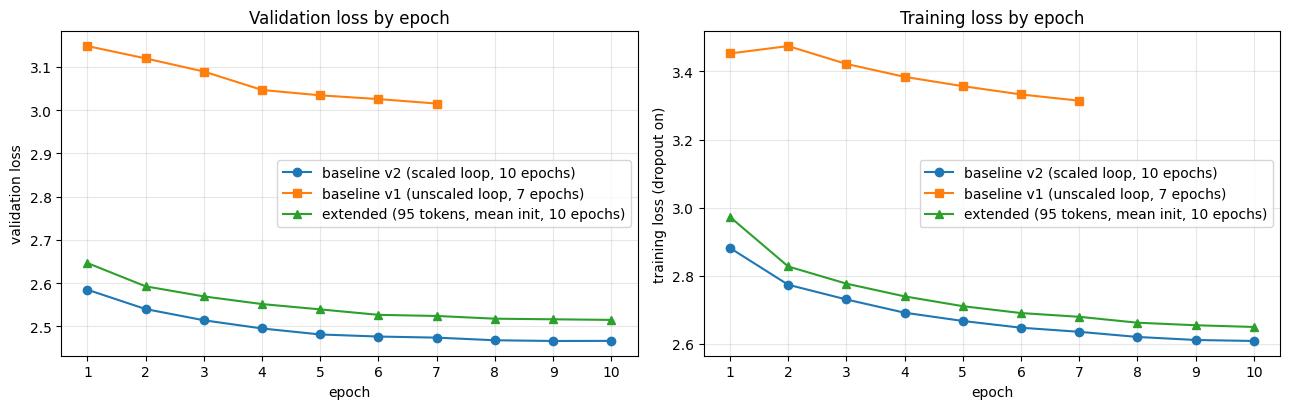

,run,epochs,epoch1_val,best_val,final_train
0,baseline v2 (scaled loop),10,2.5847,2.4662,2.6085
1,baseline v1 (unscaled loop),7,3.1481,3.0152,3.3140
2,"extended (95 tokens, mean init)",10,2.6463,2.5149,2.6497



Epoch-1 validation loss: baseline v2 2.5847 | baseline v1 3.1481 | extended 2.6463
Reduction of epoch-1 validation loss from the scaled loop alone (v1 minus v2): +0.5634
Remaining gap to the extended model at epoch 1 (v2 minus extended): -0.0616
Total skipped (non-finite / scaler-reduced) updates: 4
Note: losses are per token and the extended model tokenizes about 2% fewer tokens, so loss values are only roughly comparable across vocabularies.


In [13]:
# Section 9.1: history table and comparison plot (reference runs use their recorded values)
import matplotlib.pyplot as plt

hist_df = pd.DataFrame(S["history"])
display(hist_df.round(4))

# Reference run 1: baseline v1 (unscaled fp16 loop, 7 epochs, interrupted)
baseline_v1_train = [3.4527, 3.4744, 3.4220, 3.3841, 3.3567, 3.3324, 3.3140]
baseline_v1_val   = [3.1481, 3.1196, 3.0892, 3.0466, 3.0342, 3.0255, 3.0152]

# Reference run 2: extended model (95 tokens, mean init, 10 epochs)
extended_train = [2.9727, 2.8273, 2.7769, 2.7395, 2.7107, 2.6905, 2.6795, 2.6622, 2.6547, 2.6497]
extended_val   = [2.6463, 2.5925, 2.5692, 2.5515, 2.5392, 2.5266, 2.5240, 2.5177, 2.5163, 2.5149]

epochs_all = list(range(1, 11))
compare_df = pd.DataFrame({
    "epoch": epochs_all,
    "baseline_v2_val": hist_df.set_index("epoch")["val_loss"].reindex(epochs_all).values if len(hist_df) else [np.nan] * 10,
    "baseline_v1_val": baseline_v1_val + [np.nan] * (10 - len(baseline_v1_val)),
    "extended_val": extended_val,
    "baseline_v2_train": hist_df.set_index("epoch")["train_loss"].reindex(epochs_all).values if len(hist_df) else [np.nan] * 10,
    "baseline_v1_train": baseline_v1_train + [np.nan] * (10 - len(baseline_v1_train)),
    "extended_train": extended_train,
})
display(compare_df.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, kind in zip(axes, ["val", "train"]):
    if len(hist_df):
        ax.plot(hist_df["epoch"], hist_df["val_loss" if kind == "val" else "train_loss"],
                marker="o", label="baseline v2 (scaled loop, 10 epochs)")
    ax.plot(range(1, len(baseline_v1_val) + 1), baseline_v1_val if kind == "val" else baseline_v1_train,
            marker="s", label="baseline v1 (unscaled loop, 7 epochs)")
    ax.plot(epochs_all, extended_val if kind == "val" else extended_train,
            marker="^", label="extended (95 tokens, mean init, 10 epochs)")
    ax.set_xlabel("epoch")
    ax.set_ylabel("validation loss" if kind == "val" else "training loss (dropout on)")
    ax.set_title("Validation loss by epoch" if kind == "val" else "Training loss by epoch")
    ax.set_xticks(epochs_all); ax.grid(alpha=0.3); ax.legend()
fig.tight_layout(); fig.savefig(RUN_DIR / "loss_comparison.png", dpi=150); plt.show()

# Summary of the three runs
def _first(x): return x[0] if len(x) else np.nan
summary_rows = [
    {"run": "baseline v2 (scaled loop)", "epochs": len(hist_df),
     "epoch1_val": hist_df["val_loss"].iloc[0] if len(hist_df) else np.nan,
     "best_val": hist_df["val_loss"].min() if len(hist_df) else np.nan,
     "final_train": hist_df["train_loss"].iloc[-1] if len(hist_df) else np.nan},
    {"run": "baseline v1 (unscaled loop)", "epochs": 7,
     "epoch1_val": baseline_v1_val[0], "best_val": min(baseline_v1_val), "final_train": baseline_v1_train[-1]},
    {"run": "extended (95 tokens, mean init)", "epochs": 10,
     "epoch1_val": extended_val[0], "best_val": min(extended_val), "final_train": extended_train[-1]},
]
display(pd.DataFrame(summary_rows).round(4))

if len(hist_df):
    gap1 = baseline_v1_val[0] - hist_df["val_loss"].iloc[0]
    print(f"\nEpoch-1 validation loss: baseline v2 {hist_df['val_loss'].iloc[0]:.4f} | baseline v1 {baseline_v1_val[0]:.4f} "
          f"| extended {extended_val[0]:.4f}")
    print(f"Reduction of epoch-1 validation loss from the scaled loop alone (v1 minus v2): {gap1:+.4f}")
    print(f"Remaining gap to the extended model at epoch 1 (v2 minus extended): {hist_df['val_loss'].iloc[0] - extended_val[0]:+.4f}")
print("Total skipped (non-finite / scaler-reduced) updates:", S["skipped"])
print("Note: losses are per token and the extended model tokenizes about 2% fewer tokens, so loss values are only roughly comparable across vocabularies.")

In [14]:
# Section 9.2: back up the training run (download this zip; it lets a later session resume or evaluate)
shutil.make_archive("/kaggle/working/baseline_v2_scaled_backup", "zip", RUN_DIR)
print("Backup written: /kaggle/working/baseline_v2_scaled_backup.zip (%.1f MB)" %
      (os.path.getsize("/kaggle/working/baseline_v2_scaled_backup.zip") / 1e6))

Backup written: /kaggle/working/baseline_v2_scaled_backup.zip (52.4 MB)


## Section 10. Evaluation under one fixed pipeline
Both the new baseline and the old baseline adapter are evaluated through **exactly the same pipeline**, so any difference between them comes from the trained weights and not from inference settings:

* source prompt: `IndicProcessor`
* batch size 8, beam search `num_beams=4`, `max_length=256`, `early_stopping=True`, no sampling
* decoding with `skip_special_tokens=True`, then whitespace stripping

Evaluation sets: the first 300 validation sentences (the set used in the V1 to V4 audit) and the full 994-sentence test set. The test set is used once, for the final comparison.

In [15]:
# Section 10.1: metric helpers and bootstrap
import sacrebleu

def _has(pattern, text):
    return re.search(pattern, text) is not None

def summarize(system, split, hyp, ref):
    b = sacrebleu.corpus_bleu(hyp, [ref]); c = sacrebleu.corpus_chrf(hyp, [ref])
    return {"system": system, "split": split, "n": len(ref),
            "BLEU": round(b.score, 2), "chrF": round(c.score, 2),
            "char_len_ratio": round(sum(map(len, hyp)) / sum(map(len, ref)), 3),
            "word_len_ratio": round(sum(len(h.split()) for h in hyp) / sum(len(r.split()) for r in ref), 3),
            "ASCII_digit_%": round(100 * np.mean([_has(r"[0-9]", h) for h in hyp]), 1),
            "OlChiki_digit_%": round(100 * np.mean([_has("[\u1C50-\u1C59]", h) for h in hyp]), 1),
            "empty": sum(h == "" for h in hyp)}

def paired_bootstrap(hyp_a, hyp_b, ref, B=300, seed=0):
    # differences are B minus A
    rng = np.random.default_rng(seed)
    n = len(ref); d_bleu, d_chrf = [], []
    for _ in range(B):
        idx = rng.integers(0, n, n)
        r = [ref[i] for i in idx]; a = [hyp_a[i] for i in idx]; b = [hyp_b[i] for i in idx]
        d_bleu.append(sacrebleu.corpus_bleu(b, [r]).score - sacrebleu.corpus_bleu(a, [r]).score)
        d_chrf.append(sacrebleu.corpus_chrf(b, [r]).score - sacrebleu.corpus_chrf(a, [r]).score)
    return d_bleu, d_chrf

def show_bootstrap(label, hyp_a, hyp_b, ref):
    d_bleu, d_chrf = paired_bootstrap(hyp_a, hyp_b, ref)
    for name, d in [("BLEU", d_bleu), ("chrF", d_chrf)]:
        lo, hi = np.percentile(d, [2.5, 97.5])
        print(f"{label} | {name}: mean {np.mean(d):+.2f}, 95% interval [{lo:+.2f}, {hi:+.2f}], "
              f"B better in {100*np.mean(np.array(d) > 0):.1f}% of resamples")
print("Metric helpers ready.")

Metric helpers ready.


In [16]:
# Section 10.2: load the adapters to evaluate (new best baseline, and the old baseline if attached)
best_new = RUN_DIR / "best_adapter"
assert (best_new / "adapter_config.json").exists(), "No best_adapter found: train (Section 8) or attach a finished run."

adapter_names = ["new_baseline_v2"]
lora_model.load_adapter(str(best_new), adapter_name="new_baseline_v2")
print("Loaded new baseline (best epoch):", S["best_val"] if len(S["history"]) else "n/a",
      "| best epoch:", (min(S["history"], key=lambda r: r["val_loss"])["epoch"] if S["history"] else "n/a"))

old_hits = [h for h in glob.glob("/kaggle/input/**/best_adapter/adapter_config.json", recursive=True)
            if "baseline_v2_scaled" not in h]
if old_hits:
    old_dir = str(Path(old_hits[0]).parent)
    lora_model.load_adapter(old_dir, adapter_name="old_baseline_v1")
    adapter_names.append("old_baseline_v1")
    print("Loaded old baseline from:", old_dir)
else:
    print("Old baseline adapter not found (attach the santali_exp dataset to compare against it).")
print("Adapters to evaluate:", adapter_names)

Loaded new baseline (best epoch): 2.4661736746868455 | best epoch: 9
Loaded old baseline from: /kaggle/input/datasets/sanjeevanijaiswal/santali-exp/santali_baseline_backup/santali_baseline_backup/best_adapter
Adapters to evaluate: ['new_baseline_v2', 'old_baseline_v1']


In [17]:
# Section 10.3: generation function (the fixed evaluation pipeline)
@torch.inference_mode()
def translate(adapter_name, sources, batch_size=8):
    lora_model.set_adapter(adapter_name)
    lora_model.eval()
    prompts = [processor.preprocess_batch([s], src_lang=SRC_LANG, tgt_lang=TGT_LANG)[0] for s in sources]
    all_ids = []
    for i in range(0, len(prompts), batch_size):
        enc = tok(prompts[i:i + batch_size], padding=True, truncation=True,
                  max_length=MAX_LEN, return_tensors="pt").to(DEVICE)
        out = lora_model.generate(**enc, max_length=256, num_beams=4, early_stopping=True, do_sample=False)
        all_ids.extend(out.cpu().tolist())
    return [h.strip() for h in tok.batch_decode(all_ids, skip_special_tokens=True,
                                                clean_up_tokenization_spaces=True)]

torch.cuda.empty_cache()
EVAL_VAL_N = 300
val_src = val_df[SRC_COL].astype(str).str.strip().tolist()[:EVAL_VAL_N]
val_ref = val_df[TGT_COL].astype(str).str.strip().tolist()[:EVAL_VAL_N]
test_src = test_df[SRC_COL].astype(str).str.strip().tolist()
test_ref = test_df[TGT_COL].astype(str).str.strip().tolist()
print("Evaluation sets:", len(val_src), "validation sentences,", len(test_src), "test sentences")

Evaluation sets: 300 validation sentences, 994 test sentences


In [18]:
# Section 10.4: run generation for each adapter and save the predictions
PRED_DIR = RUN_DIR / "predictions"; PRED_DIR.mkdir(exist_ok=True)
preds = {}
for name in adapter_names:
    for split, src, ref in [("val300", val_src, val_ref), ("test", test_src, test_ref)]:
        t0 = time.time()
        hyp = translate(name, src)
        preds[(name, split)] = hyp
        pd.DataFrame({"source": src, "reference": ref, "prediction": hyp}).to_csv(
            PRED_DIR / f"{name}_{split}.csv", index=False, encoding="utf-8-sig")
        print(f"{name:18s} {split:7s} done in {(time.time()-t0)/60:.1f} min")

new_baseline_v2    val300  done in 1.1 min
new_baseline_v2    test    done in 4.7 min
old_baseline_v1    val300  done in 1.7 min
old_baseline_v1    test    done in 5.9 min


In [19]:
# Section 10.5: scores for each adapter under the identical pipeline
rows = []
for (name, split), hyp in preds.items():
    ref = val_ref if split == "val300" else test_ref
    rows.append(summarize(name, split, hyp, ref))
score_df = pd.DataFrame(rows).sort_values(["split", "system"])
display(score_df)
score_df.to_csv(RUN_DIR / "scores_fixed_pipeline.csv", index=False)

if "old_baseline_v1" in adapter_names:
    for split, ref in [("val300", val_ref), ("test", test_ref)]:
        show_bootstrap(f"new baseline v2 minus old baseline v1 [{split}]",
                       preds[("old_baseline_v1", split)], preds[("new_baseline_v2", split)], ref)

,system,split,n,BLEU,chrF,char_len_ratio,word_len_ratio,ASCII_digit_%,OlChiki_digit_%,empty
1,new_baseline_v2,test,994,12.32,45.26,1.034,1.071,0.5,0.0,0
3,old_baseline_v1,test,994,9.00,41.45,1.147,1.179,9.7,0.0,0
0,new_baseline_v2,val300,300,12.91,44.89,0.980,1.006,0.3,0.0,0
2,old_baseline_v1,val300,300,8.12,40.21,1.157,1.175,7.7,0.0,0


new baseline v2 minus old baseline v1 [val300] | BLEU: mean +4.76, 95% interval [+3.30, +6.65], B better in 100.0% of resamples
new baseline v2 minus old baseline v1 [val300] | chrF: mean +4.62, 95% interval [+3.17, +6.17], B better in 100.0% of resamples
new baseline v2 minus old baseline v1 [test] | BLEU: mean +3.31, 95% interval [+2.46, +4.22], B better in 100.0% of resamples
new baseline v2 minus old baseline v1 [test] | chrF: mean +3.78, 95% interval [+2.92, +4.68], B better in 100.0% of resamples


**How to read Section 10.5.** The two baselines are scored through the same pipeline, so the gap between them measures the effect of the training procedure alone (scaled 10-epoch loop against the unscaled 7-epoch loop).

* New baseline clearly above the old one: the old baseline was handicapped, and the earlier extended-versus-baseline gap overstated the effect of the vocabulary.
* New baseline close to the old one: the training procedure was not the cause of the gap.

## Section 11. Comparison with the extended model's existing results
The saved extended predictions (`extended_model_test_predictions.csv`) were produced with a **different pipeline** (raw prompt without `IndicProcessor`, batch size 1) and an older decoder that glued words together next to added tokens. That depresses BLEU, so the comparison below is **conservative against the extended model**:

* chrF ignores spaces in this configuration, so it is the cleaner metric here.
* If the new baseline still trails the extended model clearly on chrF despite this handicap, the conclusion that the extended model is better is robust to it.
* If the new baseline matches or beats the extended model, that is not conclusive: re-evaluate the extended checkpoint under the fixed pipeline of Section 10 for a fair comparison.

An optional added-word subset analysis and a spacing estimate run only if `candidate_lists_by_threshold.json` is attached.

In [20]:
# Section 11.1: load the existing extended predictions
def locate_file(name):
    hits = glob.glob(f"/kaggle/input/**/{name}", recursive=True) + glob.glob(f"/kaggle/working/**/{name}", recursive=True)
    return hits[0] if hits else None

ext_path = locate_file("extended_model_test_predictions.csv")
ext_pred = None
if ext_path is None:
    print("extended_model_test_predictions.csv not found: attach the santali_exp dataset to run this section.")
else:
    ext_df = pd.read_csv(ext_path, encoding="utf-8-sig")
    ext_ref = ext_df["Reference Santali"].fillna("").astype(str).str.strip().tolist()
    ext_pred = ext_df["Extended Prediction"].fillna("").astype(str).str.strip().tolist()
    print("Loaded:", ext_path, "|", len(ext_pred), "rows")
    assert len(ext_pred) == len(test_ref), "Row count differs from the test split."
    print("References identical to the test split:", ext_ref == test_ref)
    assert ext_ref == test_ref, "Reference order differs: the comparison would not be on the same sentences."

Loaded: /kaggle/input/datasets/sanjeevanijaiswal/santali-exp/extended_model_test_predictions.csv | 994 rows
References identical to the test split: True


In [21]:
# Section 11.2: optional spacing estimate for the extended predictions (needs the added-word list)
cand_path = locate_file("candidate_lists_by_threshold.json")
ext_pattern, ext_pred_repaired = None, None
if cand_path is not None:
    added_words = json.load(open(cand_path, encoding="utf-8"))["50"]
    ordered = sorted(added_words, key=lambda w: (-len(w), w))
    ext_pattern = re.compile(r"(?<!\S)(" + "|".join(re.escape(w) for w in ordered) +
                             r")(?=$|[\s\.,!?;:()\[\]{}\"'।॥])")
    rep = re.compile("(" + "|".join(re.escape(w) for w in ordered) + ")")
    def repair_spaces(s):
        s = rep.sub(lambda m: " " + m.group(1) + " ", s)
        s = re.sub(r"\s+([.,!?;:)\]}।॥])", r"\1", s)
        return re.sub(r"\s+", " ", s).strip()
    if ext_pred is not None:
        ext_pred_repaired = [repair_spaces(p) for p in ext_pred]
    print("Added-word list loaded:", len(added_words), "words")
else:
    print("candidate_lists_by_threshold.json not attached: skipping the added-word analysis and spacing estimate.")

candidate_lists_by_threshold.json not attached: skipping the added-word analysis and spacing estimate.


In [22]:
# Section 11.3: final comparison table on the test set
if ext_pred is None:
    print("Skipped: extended predictions not available.")
else:
    rows = [summarize(name, "test", preds[(name, "test")], test_ref) for name in adapter_names]
    rows.append(summarize("extended (as saved: raw prompt, old decoder)", "test", ext_pred, test_ref))
    if ext_pred_repaired is not None:
        rows.append(summarize("extended (spacing repaired, estimate)", "test", ext_pred_repaired, test_ref))
    final_df = pd.DataFrame(rows)
    display(final_df)
    final_df.to_csv(RUN_DIR / "final_comparison_test.csv", index=False)

    print("\nPaired bootstrap on the test set (sentence resampling):")
    show_bootstrap("extended (as saved) minus new baseline v2", preds[("new_baseline_v2", "test")], ext_pred, test_ref)
    if ext_pred_repaired is not None:
        show_bootstrap("extended (spacing repaired) minus new baseline v2", preds[("new_baseline_v2", "test")], ext_pred_repaired, test_ref)
    if "old_baseline_v1" in adapter_names:
        show_bootstrap("extended (as saved) minus old baseline v1", preds[("old_baseline_v1", "test")], ext_pred, test_ref)

,system,split,n,BLEU,chrF,char_len_ratio,word_len_ratio,ASCII_digit_%,OlChiki_digit_%,empty
0,new_baseline_v2,test,994,12.32,45.26,1.034,1.071,0.5,0.0,0
1,old_baseline_v1,test,994,9.00,41.45,1.147,1.179,9.7,0.0,0
2,"extended (as saved: raw prompt, old decoder)",test,994,10.83,44.84,1.026,1.044,0.4,0.0,0



Paired bootstrap on the test set (sentence resampling):
extended (as saved) minus new baseline v2 | BLEU: mean -1.53, 95% interval [-2.20, -0.87], B better in 0.0% of resamples
extended (as saved) minus new baseline v2 | chrF: mean -0.39, 95% interval [-0.97, +0.13], B better in 10.3% of resamples
extended (as saved) minus old baseline v1 | BLEU: mean +1.79, 95% interval [+0.97, +2.64], B better in 100.0% of resamples
extended (as saved) minus old baseline v1 | chrF: mean +3.39, 95% interval [+2.59, +4.27], B better in 100.0% of resamples


In [23]:
# Section 11.4: does the difference concentrate on sentences containing an added word? (optional)
if ext_pred is None or ext_pattern is None:
    print("Skipped: needs both the extended predictions and the added-word list.")
else:
    new_hyp = preds[("new_baseline_v2", "test")]
    has_added = np.array([ext_pattern.search(r) is not None for r in test_ref])
    rows = []
    for name, idx in [("all", np.arange(len(test_ref))),
                      ("reference has an added word", np.where(has_added)[0]),
                      ("reference has NO added word", np.where(~has_added)[0])]:
        r = [test_ref[i] for i in idx]
        nb_ = [new_hyp[i] for i in idx]; ex_ = [ext_pred[i] for i in idx]
        rows.append({"subset": name, "n": len(idx),
                     "new_baseline_BLEU": round(sacrebleu.corpus_bleu(nb_, [r]).score, 2),
                     "extended_BLEU": round(sacrebleu.corpus_bleu(ex_, [r]).score, 2),
                     "new_baseline_chrF": round(sacrebleu.corpus_chrf(nb_, [r]).score, 2),
                     "extended_chrF": round(sacrebleu.corpus_chrf(ex_, [r]).score, 2)})
    subset_df = pd.DataFrame(rows)
    subset_df["d_chrF"] = (subset_df["extended_chrF"] - subset_df["new_baseline_chrF"]).round(2)
    display(subset_df)
    subset_df.to_csv(RUN_DIR / "subset_added_words_test.csv", index=False)
    print("If the extended model's advantage is similar in both subsets, the added words are unlikely to be the main driver.")

Skipped: needs both the extended predictions and the added-word list.


## Section 12. Save everything
Download `baseline_v2_scaled_results.zip` before the session ends. Send me the printed outputs of Sections 8 (epoch lines), 9.1, 10.5 and 11.3.

In [46]:
# Section 12.1: final results bundle
shutil.make_archive("/kaggle/working/baseline_v2_scaled_results", "zip", RUN_DIR)
print("Results bundle: /kaggle/working/baseline_v2_scaled_results.zip (%.1f MB)" %
      (os.path.getsize("/kaggle/working/baseline_v2_scaled_results.zip") / 1e6))
for p in sorted(RUN_DIR.rglob("*")):
    if p.is_file() and p.name != "latest.pt":
        print(" -", p.relative_to(RUN_DIR), f"({p.stat().st_size/1024:.1f} KB)")

Results bundle: /kaggle/working/baseline_v2_scaled_results.zip (53.0 MB)
 - best_adapter/README.md (5.1 KB)
 - best_adapter/adapter_config.json (1.1 KB)
 - best_adapter/adapter_model.safetensors (13854.0 KB)
 - final_comparison_test.csv (0.3 KB)
 - loss_comparison.png (108.2 KB)
 - predictions/extended_fixed_test.csv (670.9 KB)
 - predictions/new_baseline_v2_test.csv (670.0 KB)
 - predictions/new_baseline_v2_val300.csv (189.0 KB)
 - predictions/old_baseline_v1_test.csv (701.3 KB)
 - predictions/old_baseline_v1_val300.csv (203.3 KB)
 - scores_fixed_pipeline.csv (0.3 KB)
 - training_history.json (3.5 KB)


# EVALUATION AND COMPARISION OF EXTENDED MODEL USING SAME ENVIRONMENT

In [25]:
from pathlib import Path
import os

INPUT_ROOT = Path("/kaggle/input")

print("Available Kaggle datasets:")
for p in sorted(INPUT_ROOT.iterdir()):
    print(f"\n{p.name}")
    for f in list(p.rglob("adapter_config.json"))[:5]:
        print("  Adapter:", f.parent)
    for f in list(p.rglob("tokenizer_config.json"))[:5]:
        print("  Tokenizer:", f.parent)
    for f in list(p.rglob("config.json"))[:5]:
        print("  Config:", f.parent)

Available Kaggle datasets:

datasets
  Adapter: /kaggle/input/datasets/sanjeevanijaiswal/santali-portable-model-bundle
  Adapter: /kaggle/input/datasets/sanjeevanijaiswal/santali-exp/santali_baseline_backup/santali_baseline_backup/best_adapter


In [26]:
from pathlib import Path
import json

EXT_BUNDLE = Path(
    "/kaggle/input/datasets/sanjeevanijaiswal/santali-portable-model-bundle"
)

print("Files in extended bundle:")
for p in sorted(EXT_BUNDLE.rglob("*")):
    if p.is_file():
        print(f"{p.relative_to(EXT_BUNDLE)} | {p.stat().st_size / (1024**2):.3f} MB")

print("\n" + "=" * 70)
print("Extended adapter configuration")
print("=" * 70)

config_path = EXT_BUNDLE / "adapter_config.json"

if config_path.exists():
    with open(config_path, "r", encoding="utf-8") as f:
        ext_config = json.load(f)
    print(json.dumps(ext_config, indent=2))
else:
    configs = list(EXT_BUNDLE.rglob("adapter_config.json"))
    if configs:
        for config_path in configs:
            print(f"\nConfig: {config_path}")
            with open(config_path, "r", encoding="utf-8") as f:
                print(json.dumps(json.load(f), indent=2))
    else:
        print("No adapter_config.json found.")

Files in extended bundle:
README.md | 0.005 MB
adapter_config.json | 0.001 MB
adapter_model.safetensors | 493.155 MB
extended_vocabulary.json | 0.006 MB
extension_weights.pt | 0.744 MB
model_metadata.json | 0.000 MB

Extended adapter configuration
{
  "alora_invocation_tokens": null,
  "alpha_pattern": {},
  "arrow_config": null,
  "auto_mapping": null,
  "base_model_name_or_path": "ai4bharat/indictrans2-indic-indic-1B",
  "bias": "none",
  "corda_config": null,
  "ensure_weight_tying": false,
  "eva_config": null,
  "exclude_modules": null,
  "fan_in_fan_out": false,
  "inference_mode": true,
  "init_lora_weights": true,
  "layer_replication": null,
  "layers_pattern": null,
  "layers_to_transform": null,
  "loftq_config": {},
  "lora_alpha": 32,
  "lora_bias": false,
  "lora_dropout": 0.05,
  "lora_ga_config": null,
  "megatron_config": null,
  "megatron_core": "megatron.core",
  "modules_to_save": null,
  "monteclora_config": null,
  "peft_type": "LORA",
  "peft_version": "0.20.0",


In [27]:
from pathlib import Path
import json
import torch
from safetensors import safe_open

EXT_BUNDLE = Path(
    "/kaggle/input/datasets/sanjeevanijaiswal/santali-portable-model-bundle"
)

# 1. Model metadata
metadata_path = EXT_BUNDLE / "model_metadata.json"
print("=== Model metadata ===")
with open(metadata_path, "r", encoding="utf-8") as f:
    metadata = json.load(f)
print(json.dumps(metadata, indent=2, ensure_ascii=False))

# 2. Extended vocabulary
vocab_path = EXT_BUNDLE / "extended_vocabulary.json"
print("\n=== Extended vocabulary ===")
with open(vocab_path, "r", encoding="utf-8") as f:
    vocab = json.load(f)

print("JSON type:", type(vocab).__name__)
if isinstance(vocab, dict):
    print("Top-level keys:", list(vocab.keys())[:20])
    for key, value in vocab.items():
        if isinstance(value, list):
            print(f"{key}: {len(value)} entries; sample:", value[:5])
        elif isinstance(value, dict):
            print(f"{key}: {len(value)} entries; sample:", list(value.items())[:5])
        else:
            print(f"{key}: {str(value)[:200]}")
elif isinstance(vocab, list):
    print("Number of entries:", len(vocab))
    print("Sample:", vocab[:10])

# 3. Extension checkpoint
extension_path = EXT_BUNDLE / "extension_weights.pt"
print("\n=== extension_weights.pt ===")
ext_state = torch.load(extension_path, map_location="cpu", weights_only=False)

if isinstance(ext_state, dict):
    print("Top-level keys:", list(ext_state.keys())[:50])
    for key, value in ext_state.items():
        if torch.is_tensor(value):
            print(f"{key}: shape={tuple(value.shape)}, dtype={value.dtype}")
        elif isinstance(value, dict):
            print(f"{key}: nested dict with {len(value)} keys; sample={list(value.keys())[:10]}")
        else:
            print(f"{key}: type={type(value).__name__}, value={str(value)[:150]}")
else:
    print("Checkpoint type:", type(ext_state).__name__)

# 4. Safetensors tensor names and shapes
adapter_path = EXT_BUNDLE / "adapter_model.safetensors"
print("\n=== adapter_model.safetensors ===")

with safe_open(str(adapter_path), framework="pt", device="cpu") as f:
    keys = list(f.keys())
    print("Tensor count:", len(keys))
    for key in keys[:30]:
        tensor = f.get_tensor(key)
        print(f"{key}: shape={tuple(tensor.shape)}, dtype={tensor.dtype}")

    if len(keys) > 30:
        print(f"... {len(keys) - 30} additional tensors")

=== Model metadata ===
{
  "base_model": "ai4bharat/indictrans2-indic-indic-1B",
  "source_language": "eng_Latn",
  "target_language": "sat_Olck",
  "max_source_length": 256,
  "max_target_length": 256,
  "base_vocab_size": 122672,
  "extended_vocab_size": 122767,
  "number_of_added_tokens": 95,
  "best_epoch": 10,
  "best_validation_loss": 2.514895272542195,
  "global_step": 11177,
  "note": "The base model is not included. Reconstruct using the matching IndicTrans2 implementation, adapter, vocabulary, and extension weights."
}

=== Extended vocabulary ===
JSON type: dict
Top-level keys: ['base_vocab_size', 'extended_vocab_size', 'candidate_to_id', 'id_to_candidate']
base_vocab_size: 122672
extended_vocab_size: 122767
candidate_to_id: 95 entries; sample: [('ᱤᱧᱟᱹᱜ', 122672), ('ᱤᱧᱤᱧ', 122673), ('ᱩᱱᱫᱚ', 122674), ('ᱫᱳᱠᱟᱱ', 122675), ('ᱢᱩᱜᱷᱚᱞ', 122676)]
id_to_candidate: 95 entries; sample: [('122672', 'ᱤᱧᱟᱹᱜ'), ('122673', 'ᱤᱧᱤᱧ'), ('122674', 'ᱩᱱᱫᱚ'), ('122675', 'ᱫᱳᱠᱟᱱ'), ('122676', 'ᱢᱩᱜᱷᱚᱞ'

In [28]:
import json
import torch
from pathlib import Path
from safetensors import safe_open

EXT_BUNDLE = Path(
    "/kaggle/input/datasets/sanjeevanijaiswal/santali-portable-model-bundle"
)

# Inspect the vocabulary IDs and verify the 95-token mapping.
with open(EXT_BUNDLE / "extended_vocabulary.json", encoding="utf-8") as f:
    vocab = json.load(f)

candidate_to_id = vocab["candidate_to_id"]
id_to_candidate = vocab["id_to_candidate"]

print("=== Vocabulary consistency ===")
print("Added-token count:", len(candidate_to_id))
print("Unique assigned IDs:", len(set(candidate_to_id.values())))
print("ID range:", min(candidate_to_id.values()), "to", max(candidate_to_id.values()))
print("Expected range:", vocab["base_vocab_size"], "to", vocab["extended_vocab_size"] - 1)

mismatches = []
for token, token_id in candidate_to_id.items():
    if id_to_candidate.get(str(token_id)) != token:
        mismatches.append((token, token_id, id_to_candidate.get(str(token_id))))

print("Reverse-mapping mismatches:", len(mismatches))
if mismatches:
    print("Examples:", mismatches[:5])

# Inspect all embedding/output-head-related adapter tensors.
adapter_path = EXT_BUNDLE / "adapter_model.safetensors"

print("\n=== Embedding/output-head tensors ===")
with safe_open(str(adapter_path), framework="pt", device="cpu") as f:
    for key in f.keys():
        if any(term in key.lower() for term in [
            "embed_tokens", "shared", "lm_head", "new_weight", "original_weight"
        ]):
            tensor = f.get_tensor(key)
            print(f"{key}: shape={tuple(tensor.shape)}, dtype={tensor.dtype}")

# Inspect saved extension tensors and compare the LM-head copy.
extension_path = EXT_BUNDLE / "extension_weights.pt"
extension = torch.load(
    extension_path, map_location="cpu", weights_only=False
)

print("\n=== Extension-weight checks ===")
for key, tensor in extension.items():
    if torch.is_tensor(tensor):
        print(
            f"{key}: shape={tuple(tensor.shape)}, "
            f"finite={bool(torch.isfinite(tensor).all())}, "
            f"mean={tensor.float().mean().item():.6f}, "
            f"std={tensor.float().std().item():.6f}"
        )

with safe_open(str(adapter_path), framework="pt", device="cpu") as f:
    if "base_model.model.lm_head.new_weight" in f.keys():
        adapter_new = f.get_tensor("base_model.model.lm_head.new_weight")
        saved_new = extension.get("lm_head_new_weight")

        if saved_new is not None and adapter_new.shape == saved_new.shape:
            print(
                "Adapter LM-head new weights equal extension checkpoint:",
                torch.allclose(
                    adapter_new.float(),
                    saved_new.float(),
                    atol=1e-6,
                    rtol=1e-5
                )
            )
        else:
            print("Could not directly compare the two LM-head weight tensors.")

=== Vocabulary consistency ===
Added-token count: 95
Unique assigned IDs: 95
ID range: 122672 to 122766
Expected range: 122672 to 122766
Reverse-mapping mismatches: 0

=== Embedding/output-head tensors ===
base_model.model.lm_head.new_weight: shape=(95, 1024), dtype=torch.float32
base_model.model.lm_head.original_weight: shape=(122672, 1024), dtype=torch.float16
base_model.model.model.encoder.embed_tokens.weight: shape=(122706, 1024), dtype=torch.float16

=== Extension-weight checks ===
decoder_new_weight: shape=(95, 1024), finite=True, mean=-0.004156, std=0.038505
lm_head_new_weight: shape=(95, 1024), finite=True, mean=0.002286, std=0.035868
Adapter LM-head new weights equal extension checkpoint: True


In [29]:
import json
import torch
from pathlib import Path
from safetensors import safe_open

EXT_BUNDLE = Path(
    "/kaggle/input/datasets/sanjeevanijaiswal/santali-portable-model-bundle"
)

# Inspect the vocabulary IDs and verify the 95-token mapping.
with open(EXT_BUNDLE / "extended_vocabulary.json", encoding="utf-8") as f:
    vocab = json.load(f)

candidate_to_id = vocab["candidate_to_id"]
id_to_candidate = vocab["id_to_candidate"]

print("=== Vocabulary consistency ===")
print("Added-token count:", len(candidate_to_id))
print("Unique assigned IDs:", len(set(candidate_to_id.values())))
print("ID range:", min(candidate_to_id.values()), "to", max(candidate_to_id.values()))
print("Expected range:", vocab["base_vocab_size"], "to", vocab["extended_vocab_size"] - 1)

mismatches = []
for token, token_id in candidate_to_id.items():
    if id_to_candidate.get(str(token_id)) != token:
        mismatches.append((token, token_id, id_to_candidate.get(str(token_id))))

print("Reverse-mapping mismatches:", len(mismatches))
if mismatches:
    print("Examples:", mismatches[:5])

# Inspect all embedding/output-head-related adapter tensors.
adapter_path = EXT_BUNDLE / "adapter_model.safetensors"

print("\n=== Embedding/output-head tensors ===")
with safe_open(str(adapter_path), framework="pt", device="cpu") as f:
    for key in f.keys():
        if any(term in key.lower() for term in [
            "embed_tokens", "shared", "lm_head", "new_weight", "original_weight"
        ]):
            tensor = f.get_tensor(key)
            print(f"{key}: shape={tuple(tensor.shape)}, dtype={tensor.dtype}")

# Inspect saved extension tensors and compare the LM-head copy.
extension_path = EXT_BUNDLE / "extension_weights.pt"
extension = torch.load(
    extension_path, map_location="cpu", weights_only=False
)

print("\n=== Extension-weight checks ===")
for key, tensor in extension.items():
    if torch.is_tensor(tensor):
        print(
            f"{key}: shape={tuple(tensor.shape)}, "
            f"finite={bool(torch.isfinite(tensor).all())}, "
            f"mean={tensor.float().mean().item():.6f}, "
            f"std={tensor.float().std().item():.6f}"
        )

with safe_open(str(adapter_path), framework="pt", device="cpu") as f:
    if "base_model.model.lm_head.new_weight" in f.keys():
        adapter_new = f.get_tensor("base_model.model.lm_head.new_weight")
        saved_new = extension.get("lm_head_new_weight")

        if saved_new is not None and adapter_new.shape == saved_new.shape:
            print(
                "Adapter LM-head new weights equal extension checkpoint:",
                torch.allclose(
                    adapter_new.float(),
                    saved_new.float(),
                    atol=1e-6,
                    rtol=1e-5
                )
            )
        else:
            print("Could not directly compare the two LM-head weight tensors.")

=== Vocabulary consistency ===
Added-token count: 95
Unique assigned IDs: 95
ID range: 122672 to 122766
Expected range: 122672 to 122766
Reverse-mapping mismatches: 0

=== Embedding/output-head tensors ===
base_model.model.lm_head.new_weight: shape=(95, 1024), dtype=torch.float32
base_model.model.lm_head.original_weight: shape=(122672, 1024), dtype=torch.float16
base_model.model.model.encoder.embed_tokens.weight: shape=(122706, 1024), dtype=torch.float16

=== Extension-weight checks ===
decoder_new_weight: shape=(95, 1024), finite=True, mean=-0.004156, std=0.038505
lm_head_new_weight: shape=(95, 1024), finite=True, mean=0.002286, std=0.035868
Adapter LM-head new weights equal extension checkpoint: True


In [30]:
# Reconstruct the saved extended-vocabulary model for fair evaluation.
# Reuses the existing environment; does not retrain the model.

import gc
import json
import torch
import torch.nn as nn
import torch.nn.functional as F

from pathlib import Path
from safetensors.torch import load_file
from transformers import AutoModelForSeq2SeqLM
from peft import LoraConfig, get_peft_model, TaskType, set_peft_model_state_dict

EXT_BUNDLE = Path(
    "/kaggle/input/datasets/sanjeevanijaiswal/santali-portable-model-bundle"
)

with open(EXT_BUNDLE / "model_metadata.json", encoding="utf-8") as f:
    ext_meta = json.load(f)

with open(EXT_BUNDLE / "extended_vocabulary.json", encoding="utf-8") as f:
    ext_vocab = json.load(f)

BASE_TARGET_VOCAB_SIZE = ext_meta["base_vocab_size"]
EXTENDED_TARGET_VOCAB_SIZE = ext_meta["extended_vocab_size"]

# Custom modules: frozen original rows + saved extension rows.
class FrozenBaseExtendedEmbedding(nn.Module):
    def __init__(self, original_weight, new_weight, padding_idx=None):
        super().__init__()
        self.original_weight = nn.Parameter(
            original_weight.detach().clone(), requires_grad=False
        )
        self.new_weight = nn.Parameter(
            new_weight.detach().clone().float(), requires_grad=False
        )
        self.padding_idx = padding_idx
        self.original_vocab_size = original_weight.shape[0]
        self.num_new_tokens = new_weight.shape[0]
        self.embedding_dim = original_weight.shape[1]

    @property
    def weight(self):
        return torch.cat([self.original_weight, self.new_weight], dim=0)

    @property
    def num_embeddings(self):
        return self.original_vocab_size + self.num_new_tokens

    def forward(self, input_ids):
        weight = torch.cat(
            [self.original_weight, self.new_weight], dim=0
        ).to(self.original_weight.dtype)
        return F.embedding(input_ids, weight, padding_idx=self.padding_idx)


class FrozenBaseExtendedLMHead(nn.Module):
    def __init__(self, original_weight, new_weight, bias=None):
        super().__init__()
        self.original_weight = nn.Parameter(
            original_weight.detach().clone(), requires_grad=False
        )
        self.new_weight = nn.Parameter(
            new_weight.detach().clone().float(), requires_grad=False
        )
        if bias is None:
            self.register_parameter("bias", None)
        else:
            self.bias = nn.Parameter(bias.detach().clone(), requires_grad=False)
        self.original_vocab_size = original_weight.shape[0]
        self.num_new_tokens = new_weight.shape[0]
        self.hidden_size = original_weight.shape[1]

    @property
    def weight(self):
        return torch.cat([self.original_weight, self.new_weight], dim=0)

    @property
    def out_features(self):
        return self.original_vocab_size + self.num_new_tokens

    @property
    def in_features(self):
        return self.hidden_size

    def forward(self, hidden_states):
        weight = torch.cat(
            [self.original_weight, self.new_weight], dim=0
        ).to(hidden_states.dtype)
        bias = self.bias
        if bias is not None:
            bias = bias.to(hidden_states.dtype)
        return F.linear(hidden_states, weight, bias)


# Load the original base model, then create the matching LoRA structure.
print("Loading base model...")
base = AutoModelForSeq2SeqLM.from_pretrained(
    ext_meta["base_model"],
    trust_remote_code=True,
    token=hf_token,
    torch_dtype=torch.float16,
    low_cpu_mem_usage=True,
).to(DEVICE)

lora_cfg = LoraConfig(
    r=16,
    lora_alpha=32,
    target_modules=["q_proj", "v_proj"],
    lora_dropout=0.05,
    bias="none",
    task_type=TaskType.SEQ_2_SEQ_LM,
)

extended_model = get_peft_model(base, lora_cfg)
base_model = extended_model.base_model.model
decoder = base_model.model.decoder

# Expand only the target-side decoder embedding and LM head.
old_embedding = decoder.embed_tokens
old_lm_head = base_model.lm_head

assert old_embedding.weight.shape[0] == BASE_TARGET_VOCAB_SIZE
assert old_lm_head.weight.shape[0] == BASE_TARGET_VOCAB_SIZE

decoder.embed_tokens = FrozenBaseExtendedEmbedding(
    old_embedding.weight,
    torch.zeros(
        len(ext_vocab["candidate_to_id"]), old_embedding.weight.shape[1]
    ),
    padding_idx=old_embedding.padding_idx,
).to(DEVICE)

base_model.lm_head = FrozenBaseExtendedLMHead(
    old_lm_head.weight,
    torch.zeros(
        len(ext_vocab["candidate_to_id"]), old_lm_head.weight.shape[1]
    ),
    bias=old_lm_head.bias,
).to(DEVICE)

base_model.config.vocab_size = EXTENDED_TARGET_VOCAB_SIZE
base_model.config.decoder_vocab_size = EXTENDED_TARGET_VOCAB_SIZE
extended_model.config.vocab_size = EXTENDED_TARGET_VOCAB_SIZE
extended_model.config.decoder_vocab_size = EXTENDED_TARGET_VOCAB_SIZE

# Restore the saved LoRA adapter and its associated custom-module state.
adapter_state = load_file(
    str(EXT_BUNDLE / "adapter_model.safetensors"),
    device="cpu",
)
adapter_result = set_peft_model_state_dict(extended_model, adapter_state)

# Explicitly restore the learned extension rows from the portable checkpoint.
extension = torch.load(
    EXT_BUNDLE / "extension_weights.pt",
    map_location="cpu",
    weights_only=False,
)

with torch.no_grad():
    decoder.embed_tokens.new_weight.copy_(
        extension["decoder_new_weight"].to(DEVICE)
    )
    base_model.lm_head.new_weight.copy_(
        extension["lm_head_new_weight"].to(DEVICE)
    )

extended_model.eval()

# Confirm reconstruction before running the evaluation.
print("\n=== Reconstruction checks ===")
print("Adapter loaded; unexpected keys:", getattr(adapter_result, "unexpected_keys", []))
print("Extended vocabulary:", base_model.lm_head.out_features)
print("Decoder extension:", tuple(decoder.embed_tokens.new_weight.shape))
print("LM-head extension:", tuple(base_model.lm_head.new_weight.shape))
print("Decoder extension finite:",
      bool(torch.isfinite(decoder.embed_tokens.new_weight).all()))
print("LM-head extension finite:",
      bool(torch.isfinite(base_model.lm_head.new_weight).all()))
print("Model device:", next(extended_model.parameters()).device)

assert base_model.lm_head.out_features == EXTENDED_TARGET_VOCAB_SIZE
assert decoder.embed_tokens.new_weight.shape[0] == 95
assert base_model.lm_head.new_weight.shape[0] == 95
assert torch.isfinite(decoder.embed_tokens.new_weight).all()
assert torch.isfinite(base_model.lm_head.new_weight).all()

print("\nPASS: extended model reconstructed.")

Loading base model...

=== Reconstruction checks ===
Adapter loaded; unexpected keys: []
Extended vocabulary: 122767
Decoder extension: (95, 1024)
LM-head extension: (95, 1024)
Decoder extension finite: True
LM-head extension finite: True
Model device: cuda:0

PASS: extended model reconstructed.


In [32]:
# Sanity check using the exact preprocessing variables from Baseline v2.

sample_english = str(test_df[SRC_COL].iloc[0]).strip()
sample_santali = str(test_df[TGT_COL].iloc[0]).strip()

sample_processed = processor.preprocess_batch(
    [sample_english],
    src_lang=SRC_LANG,
    tgt_lang=TGT_LANG,
)

sample_inputs = tok(
    sample_processed,
    padding=True,
    truncation=True,
    max_length=MAX_LEN,
    return_tensors="pt",
).to(DEVICE)

extended_model.eval()

with torch.inference_mode():
    sample_output_ids = extended_model.generate(
        **sample_inputs,
        max_length=256,
        num_beams=4,
        early_stopping=True,
        do_sample=False,
    )

sample_prediction = tok.batch_decode(
    sample_output_ids.cpu(),
    skip_special_tokens=True,
    clean_up_tokenization_spaces=True,
)[0].strip()

print("English source:", sample_english)
print("Reference Santali:", sample_santali)
print("Extended-model prediction:", sample_prediction)
print("Generated token count:", sample_output_ids.shape[1])

English source: Puducherry is one of the most popular tourist spots in India for national and international tourists.
Reference Santali: ᱡᱟᱹᱛᱤᱭᱟᱨᱤ ᱟᱨ ᱡᱮᱜᱮᱫ ᱡᱟᱠᱟᱫ ᱥᱟᱸᱜᱷᱟᱨᱤᱭᱟᱹ ᱠᱚᱴᱷᱮᱱ ᱯᱩᱫᱩᱪᱮᱨᱤ ᱫᱚ ᱦᱩᱭᱩᱜ ᱠᱟᱱᱟ ᱵᱷᱟᱨᱚᱛ ᱨᱮᱭᱟᱜ ᱥᱚᱨᱮᱥ ᱧᱩᱢᱡᱚᱝ ᱥᱟᱸᱜᱷᱟᱨ ᱴᱷᱟᱣ ᱾
Extended-model prediction: ᱯᱩᱫᱩᱪᱮᱨᱤ ᱡᱟᱹᱛᱤᱭᱟᱹᱨᱤ ᱟᱨ ᱡᱮᱜᱮᱫ ᱡᱟᱠᱟᱛ ᱥᱟᱸᱜᱷᱟᱨᱤᱭᱟᱹ ᱠᱚ ᱞᱟᱹᱜᱤᱫ ᱵᱷᱟᱨᱚᱛ ᱨᱮᱭᱟᱜ ᱥᱚᱨᱮᱥ ᱦᱚᱲ ᱠᱩᱥᱤ ᱥᱟᱸᱜᱷᱟᱨ ᱴᱷᱟᱶ ᱠᱟᱱᱟ ᱾
Generated token count: 21


In [33]:
# Fair full-test evaluation of the extended model using Baseline v2's
# preprocessing and generation settings, with extension-aware decoding.

import pandas as pd
import torch
from tqdm.auto import tqdm

BASE_VOCAB_SIZE = 122672
id_to_candidate = {
    int(token_id): word
    for word, token_id in ext_vocab["candidate_to_id"].items()
}

def decode_extended_ids(token_ids):
    if isinstance(token_ids, torch.Tensor):
        token_ids = token_ids.detach().cpu().tolist()

    eos_id = extended_model.config.eos_token_id
    pad_id = extended_model.config.pad_token_id
    decoder_start_id = extended_model.config.decoder_start_token_id

    if token_ids and int(token_ids[0]) == decoder_start_id:
        token_ids = token_ids[1:]

    parts = []
    original_ids = []

    def flush_original():
        if original_ids:
            parts.append(
                tok.decode(
                    original_ids,
                    skip_special_tokens=True,
                    clean_up_tokenization_spaces=False,
                )
            )
            original_ids.clear()

    for token_id in token_ids:
        token_id = int(token_id)

        if token_id == eos_id:
            break
        if pad_id is not None and token_id == pad_id:
            continue

        if token_id >= BASE_VOCAB_SIZE:
            flush_original()
            if token_id not in id_to_candidate:
                raise ValueError(f"Unknown extension token ID: {token_id}")
            parts.append(id_to_candidate[token_id])
        else:
            original_ids.append(token_id)

    flush_original()
    return "".join(parts).strip()


extended_model.eval()

eval_sources = test_df[SRC_COL].fillna("").astype(str).str.strip().tolist()
eval_references = test_df[TGT_COL].fillna("").astype(str).str.strip().tolist()
extended_predictions_fair = []

with torch.inference_mode():
    for start in tqdm(
        range(0, len(eval_sources), 8),
        desc="Extended model — fixed test pipeline",
    ):
        batch_sources = eval_sources[start:start + 8]

        prompts = [
            processor.preprocess_batch(
                [source],
                src_lang=SRC_LANG,
                tgt_lang=TGT_LANG,
            )[0]
            for source in batch_sources
        ]

        enc = tok(
            prompts,
            padding=True,
            truncation=True,
            max_length=MAX_LEN,
            return_tensors="pt",
        ).to(DEVICE)

        generated = extended_model.generate(
            **enc,
            max_length=256,
            num_beams=4,
            early_stopping=True,
            do_sample=False,
        )

        extended_predictions_fair.extend(
            decode_extended_ids(ids) for ids in generated
        )

assert len(extended_predictions_fair) == len(eval_references)

extended_fair_df = pd.DataFrame({
    "English": eval_sources,
    "Reference Santali": eval_references,
    "Extended Prediction": extended_predictions_fair,
})

print("Test examples:", len(extended_fair_df))
print("Empty predictions:",
      (extended_fair_df["Extended Prediction"].str.strip() == "").sum())
print("Predictions using added tokens:",
      sum(
          any(int(t) >= BASE_VOCAB_SIZE for t in ids.tolist())
          for ids in []
      ))

display(extended_fair_df.head(5))

Extended model — fixed test pipeline:   0%|          | 0/125 [00:00<?, ?it/s]

Test examples: 994
Empty predictions: 0
Predictions using added tokens: 0


,English,Reference Santali,Extended Prediction
0,Puducherry is one of the most popular tourist ...,ᱡᱟᱹᱛᱤᱭᱟᱨᱤ ᱟᱨ ᱡᱮᱜᱮᱫ ᱡᱟᱠᱟᱫ ᱥᱟᱸᱜᱷᱟᱨᱤᱭᱟᱹ ᱠᱚᱴᱷᱮᱱ ᱯᱩ...,ᱯᱩᱫᱩᱪᱮᱨᱤ ᱡᱟᱹᱛᱤᱭᱟᱹᱨᱤ ᱟᱨ ᱡᱮᱜᱮᱫ ᱡᱟᱠᱟᱛ ᱥᱟᱸᱜᱷᱟᱨᱤᱭᱟᱹ...
1,She is widely regarded in modern Indian histor...,ᱱᱟᱦᱟᱜ ᱵᱷᱟᱨᱚᱛᱤᱭᱚ ᱱᱟᱜᱟᱢ ᱚᱞ ᱨᱮ ᱩᱱᱤ ᱫᱚ ᱟᱹᱰᱤ ᱛᱮᱫ ᱜᱮ...,ᱩᱱᱤ ᱫᱚ ᱱᱟᱦᱟᱜ ᱵᱷᱟᱨᱚᱛ ᱨᱮᱭᱟᱜ ᱱᱟᱜᱟᱢ ᱪᱤᱛᱟᱹᱨ ᱨᱮ ᱟᱠᱵᱚ...
2,"This way, the Robo advisor can go from giving ...","ᱱᱚᱶᱟ ᱞᱮᱠᱟᱛᱮ, ᱯᱚᱨᱟᱢᱮᱥ ᱮᱢ ᱠᱷᱚᱱ ᱮᱦᱚᱵ ᱠᱟᱛᱮᱜ ᱯᱨᱚᱠᱤᱛ...",ᱱᱚᱶᱟ ᱞᱮᱠᱟᱛᱮ ᱨᱳᱵᱳ ᱫᱤᱥᱦᱩᱫᱤᱥ ᱮᱢᱚᱜᱤᱡ ᱟᱢᱟᱜ ᱠᱟᱹᱣᱰᱤ ᱥ...
3,He hung the portraits of all these three perso...,ᱩᱱᱤ ᱫᱚ ᱟᱭᱟᱜ ᱜᱳᱣᱨᱤ ᱠᱩᱧᱡᱚ ᱨᱮᱱᱟᱜ ᱛᱟᱦᱮᱱ ᱚᱲᱟᱜ ᱨᱮ ᱱᱩ...,ᱩᱱᱤ ᱫᱚ ᱟᱭᱟᱜ ᱜᱳᱣᱨᱤ ᱠᱩᱱ ᱟᱜ ᱚᱲᱟᱜ ᱨᱮ ᱱᱚᱣᱟ ᱯᱮᱭᱟ ᱦᱚᱲ...
4,I am unsure about driving in the US after driv...,ᱤᱧ ᱵᱷᱟᱨᱚᱛ ᱨᱮ ᱜᱟᱹᱰᱤ ᱪᱟᱞᱟᱣ ᱛᱟᱭᱚᱢ ᱢᱟᱨᱠᱤᱱ ᱡᱩᱠᱛᱚ ᱨᱟ...,ᱵᱷᱟᱨᱚᱛ ᱨᱮ ᱜᱟᱹᱰᱤ ᱪᱟᱞᱟᱣ ᱛᱟᱭᱚᱢ ᱤᱧ ᱢᱟᱨᱠᱤᱱ ᱡᱩᱠᱛᱚᱨᱟᱥ...


In [44]:
import sacrebleu
import pandas as pd
import numpy as np

# Score the extended model on the fixed 994-sentence test set.
extended_scores = {
    "System": "Extended vocabulary model",
    "N": len(eval_references),
    "BLEU": round(
        sacrebleu.corpus_bleu(
            extended_predictions_fair, [eval_references]
        ).score, 2
    ),
    "chrF": round(
        sacrebleu.corpus_chrf(
            extended_predictions_fair, [eval_references]
        ).score, 2
    ),
    "Empty predictions": sum(
        not p.strip() for p in extended_predictions_fair
    ),
}

rows = [extended_scores]

# Compare against Baseline v2 only if its predictions exist in this session.
baseline_hyp = None

if "preds" in globals() and ("new_baseline_v2", "test") in preds:
    baseline_hyp = preds[("new_baseline_v2", "test")]
elif "baseline_predictions" in globals():
    baseline_hyp = baseline_predictions

if baseline_hyp is not None:
    baseline_hyp = [str(p).strip() for p in baseline_hyp]
    assert len(baseline_hyp) == len(eval_references), (
        "Baseline prediction count differs from the test set."
    )

    rows.insert(0, {
        "System": "Baseline v2",
        "N": len(eval_references),
        "BLEU": round(
            sacrebleu.corpus_bleu(baseline_hyp, [eval_references]).score, 2
        ),
        "chrF": round(
            sacrebleu.corpus_chrf(baseline_hyp, [eval_references]).score, 2
        ),
        "Empty predictions": sum(not p for p in baseline_hyp),
    })

    print("Differences below are Extended model minus Baseline v2.")
    print(
        "BLEU difference:",
        round(extended_scores["BLEU"] - rows[0]["BLEU"], 2)
    )
    print(
        "chrF difference:",
        round(extended_scores["chrF"] - rows[0]["chrF"], 2)
    )
else:
    print(
        "Baseline v2 predictions are not available in this session; "
        "reporting extended-model scores only."
    )

display(pd.DataFrame(rows))

Differences below are Extended model minus Baseline v2.
BLEU difference: 0.06
chrF difference: 0.38


,System,N,BLEU,chrF,Empty predictions
0,Baseline v2,994,12.32,45.26,0
1,Extended vocabulary model,994,12.38,45.64,0


In [45]:

# =============================================================================
# Comprehensive Side-by-Side Evaluation: Baseline v2 vs Extended Vocabulary
# =============================================================================

import numpy as np
import pandas as pd
import sacrebleu
import re
from IPython.display import display

# 1. Get baseline predictions from the existing notebook session
if "preds" in globals() and ("new_baseline_v2", "test") in preds:
    baseline_preds = preds[("new_baseline_v2", "test")]
elif "baseline_predictions" in globals():
    baseline_preds = baseline_predictions
else:
    raise NameError(
        "Baseline predictions not found. Load the saved Baseline v2 "
        "predictions before running this evaluation."
    )

# 2. Use the already generated extended-model predictions
assert "extended_predictions_fair" in globals(), \
    "extended_predictions_fair is missing. Run extended-model inference first."
assert "eval_references" in globals(), \
    "eval_references is missing. Run the existing test preparation cell first."

references = [str(x).strip() for x in eval_references]
systems = {
    "Baseline v2": [str(x).strip() for x in baseline_preds],
    "Extended vocabulary": [
        str(x).strip() for x in extended_predictions_fair
    ],
}

for name, predictions in systems.items():
    assert len(predictions) == len(references), (
        f"{name}: {len(predictions)} predictions vs "
        f"{len(references)} references."
    )

# 3. Text-level diagnostic helpers
def words(text):
    return re.findall(r"\S+", str(text).strip())

def corpus_metrics(predictions, refs):
    bleu = sacrebleu.corpus_bleu(predictions, [refs])
    chrf = sacrebleu.corpus_chrf(predictions, [refs])
    ter = sacrebleu.corpus_ter(predictions, [refs])

    # Exact string match after trimming outer whitespace
    exact_match = np.mean([
        p == r for p, r in zip(predictions, refs)
    ]) * 100

    # Token/word overlap: corpus-level unigram precision, recall, F1.
    # This is a diagnostic, not a substitute for BLEU or chrF.
    overlap, pred_total, ref_total = 0, 0, 0
    for pred, ref in zip(predictions, refs):
        pw, rw = words(pred), words(ref)
        from collections import Counter
        pc, rc = Counter(pw), Counter(rw)
        overlap += sum((pc & rc).values())
        pred_total += len(pw)
        ref_total += len(rw)

    precision = 100 * overlap / pred_total if pred_total else 0.0
    recall = 100 * overlap / ref_total if ref_total else 0.0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0.0
    )

    pred_lengths = np.array([len(words(p)) for p in predictions])
    ref_lengths = np.array([len(words(r)) for r in refs])
    char_lengths = np.array([len(p) for p in predictions])

    return {
        "Examples": len(predictions),
        "BLEU": bleu.score,
        "chrF": chrf.score,
        "TER (lower better)": ter.score,
        "Exact match (%)": exact_match,
        "Unigram precision (%)": precision,
        "Unigram recall (%)": recall,
        "Unigram F1 (%)": f1,
        "Empty predictions": sum(not p for p in predictions),
        "Predictions with whitespace": sum(bool(p) for p in predictions),
        "Mean prediction words": pred_lengths.mean(),
        "Mean reference words": ref_lengths.mean(),
        "Prediction/reference length ratio": (
            pred_lengths.sum() / ref_lengths.sum()
            if ref_lengths.sum() else np.nan
        ),
        "Mean prediction characters": char_lengths.mean(),
        "Distinct prediction rate (%)": (
            100 * len(set(predictions)) / len(predictions)
            if predictions else 0.0
        ),
    }

# 4. Compute metrics
metrics = {
    name: corpus_metrics(preds_list, references)
    for name, preds_list in systems.items()
}

comparison = pd.DataFrame(metrics).T
comparison.index.name = "System"

# Keep display readable
display(comparison.round(3))

# 5. Difference table: Extended minus Baseline
diff = {}
for metric in comparison.columns:
    if metric == "Examples":
        continue
    diff[metric] = (
        comparison.loc["Extended vocabulary", metric]
        - comparison.loc["Baseline v2", metric]
    )

diff_df = pd.DataFrame(
    {"Extended − Baseline": pd.Series(diff)}
)
print("\nMetric differences (Extended − Baseline):")
display(diff_df.round(3))

# 6. Paired per-example diagnostic table
paired_df = pd.DataFrame({
    "English": eval_sources if "eval_sources" in globals() else [""] * len(references),
    "Reference": references,
    "Baseline prediction": systems["Baseline v2"],
    "Extended prediction": systems["Extended vocabulary"],
})

paired_df["Baseline exact match"] = (
    paired_df["Baseline prediction"] == paired_df["Reference"]
)
paired_df["Extended exact match"] = (
    paired_df["Extended prediction"] == paired_df["Reference"]
)
paired_df["Baseline word count"] = paired_df["Baseline prediction"].map(
    lambda x: len(words(x))
)
paired_df["Extended word count"] = paired_df["Extended prediction"].map(
    lambda x: len(words(x))
)
paired_df["Reference word count"] = paired_df["Reference"].map(
    lambda x: len(words(x))
)
paired_df["Extended − Baseline word count"] = (
    paired_df["Extended word count"] - paired_df["Baseline word count"]
)

print("\nPer-example comparison preview:")
display(paired_df.head(10))

# 7. Show examples where the systems differ most in exact-match status
changed_exact = paired_df[
    paired_df["Baseline exact match"] != paired_df["Extended exact match"]
]
print(
    f"\nExamples where exact-match status changed: "
    f"{len(changed_exact)} / {len(paired_df)}"
)
display(changed_exact.head(10))

print(
    "\nInterpretation note: BLEU, chrF and TER are corpus-level metrics. "
    "Exact match and unigram overlap are additional diagnostics. "
    "A positive difference is not automatically statistically significant."
)


,Examples,BLEU,chrF,TER (lower better),Exact match (%),Unigram precision (%),Unigram recall (%),Unigram F1 (%),Empty predictions,Predictions with whitespace,Mean prediction words,Mean reference words,Prediction/reference length ratio,Mean prediction characters,Distinct prediction rate (%)
System,,,,,,,,,,,,,,,
Baseline v2,994.0,12.324,45.258,76.991,0.101,41.430,44.382,42.855,0.0,994.0,20.825,19.44,1.071,112.913,99.799
Extended vocabulary,994.0,12.379,45.635,77.597,0.101,41.646,45.216,43.358,0.0,994.0,21.106,19.44,1.086,113.418,99.799



Metric differences (Extended − Baseline):


,Extended − Baseline
BLEU,0.055
chrF,0.377
TER (lower better),0.605
Exact match (%),0.000
Unigram precision (%),0.216
Unigram recall (%),0.833
Unigram F1 (%),0.502
Empty predictions,0.000
Predictions with whitespace,0.000
Mean prediction words,0.281



Per-example comparison preview:


,English,Reference,Baseline prediction,Extended prediction,Baseline exact match,Extended exact match,Baseline word count,Extended word count,Reference word count,Extended − Baseline word count
0,Puducherry is one of the most popular tourist ...,ᱡᱟᱹᱛᱤᱭᱟᱨᱤ ᱟᱨ ᱡᱮᱜᱮᱫ ᱡᱟᱠᱟᱫ ᱥᱟᱸᱜᱷᱟᱨᱤᱭᱟᱹ ᱠᱚᱴᱷᱮᱱ ᱯᱩ...,ᱯᱩᱫᱩᱪᱮᱨᱤ ᱵᱷᱟᱨᱚᱛ ᱨᱮᱭᱟᱜ ᱡᱟᱹᱛᱤᱭᱟᱹᱨᱤ ᱟᱨ ᱡᱮᱜᱮᱫ ᱡᱟᱠᱟ...,ᱯᱩᱫᱩᱪᱮᱨᱤ ᱡᱟᱹᱛᱤᱭᱟᱹᱨᱤ ᱟᱨ ᱡᱮᱜᱮᱫ ᱡᱟᱠᱟᱛ ᱥᱟᱸᱜᱷᱟᱨᱤᱭᱟᱹ...,False,False,20,17,17,-3
1,She is widely regarded in modern Indian histor...,ᱱᱟᱦᱟᱜ ᱵᱷᱟᱨᱚᱛᱤᱭᱚ ᱱᱟᱜᱟᱢ ᱚᱞ ᱨᱮ ᱩᱱᱤ ᱫᱚ ᱟᱹᱰᱤ ᱛᱮᱫ ᱜᱮ...,ᱩᱱᱤ ᱫᱚ ᱱᱟᱦᱟᱜ ᱵᱷᱟᱨᱚᱛ ᱨᱮᱭᱟᱜ ᱱᱟᱜᱟᱢ ᱪᱤᱛᱟᱹᱨ ᱨᱮ ᱟᱠᱵᱚ...,ᱩᱱᱤ ᱫᱚ ᱱᱟᱦᱟᱜ ᱵᱷᱟᱨᱚᱛ ᱨᱮᱭᱟᱜ ᱱᱟᱜᱟᱢ ᱪᱤᱛᱟᱹᱨ ᱨᱮ ᱟᱠᱵᱚ...,False,False,35,38,37,3
2,"This way, the Robo advisor can go from giving ...","ᱱᱚᱶᱟ ᱞᱮᱠᱟᱛᱮ, ᱯᱚᱨᱟᱢᱮᱥ ᱮᱢ ᱠᱷᱚᱱ ᱮᱦᱚᱵ ᱠᱟᱛᱮᱜ ᱯᱨᱚᱠᱤᱛ...",ᱱᱚᱝᱠᱟ ᱠᱟᱛᱮ ᱨᱳᱵᱳ ᱥᱟᱞᱦᱟ ᱮᱢᱚᱜᱤᱡ ᱟᱢᱟᱜ ᱠᱟᱹᱣᱰᱤ ᱥᱟᱧᱪᱟ...,ᱱᱚᱶᱟ ᱞᱮᱠᱟᱛᱮ ᱨᱳᱵᱳ ᱫᱤᱥᱦᱩᱫᱤᱥ ᱮᱢᱚᱜᱤᱡ ᱟᱢᱟᱜ ᱠᱟᱹᱣᱰᱤ ᱥ...,False,False,14,14,19,0
3,He hung the portraits of all these three perso...,ᱩᱱᱤ ᱫᱚ ᱟᱭᱟᱜ ᱜᱳᱣᱨᱤ ᱠᱩᱧᱡᱚ ᱨᱮᱱᱟᱜ ᱛᱟᱦᱮᱱ ᱚᱲᱟᱜ ᱨᱮ ᱱᱩ...,ᱩᱱᱤ ᱫᱚ ᱟᱭᱟᱜ ᱜᱳᱣᱨᱤ ᱠᱩᱱ ᱟᱜ ᱚᱲᱟᱜ ᱨᱮ ᱱᱚᱣᱟ ᱯᱮᱭᱟ ᱦᱚᱲ...,ᱩᱱᱤ ᱫᱚ ᱟᱭᱟᱜ ᱜᱳᱣᱨᱤ ᱠᱩᱱ ᱟᱜ ᱚᱲᱟᱜ ᱨᱮ ᱱᱚᱣᱟ ᱯᱮᱭᱟ ᱦᱚᱲ...,False,False,31,31,34,0
4,I am unsure about driving in the US after driv...,ᱤᱧ ᱵᱷᱟᱨᱚᱛ ᱨᱮ ᱜᱟᱹᱰᱤ ᱪᱟᱞᱟᱣ ᱛᱟᱭᱚᱢ ᱢᱟᱨᱠᱤᱱ ᱡᱩᱠᱛᱚ ᱨᱟ...,ᱤᱧ ᱵᱷᱟᱨᱚᱛ ᱨᱮ ᱰᱨᱟᱭᱵᱷᱤᱝ ᱛᱟᱭᱚᱢ ᱢᱟᱨᱠᱤᱱ ᱡᱩᱠᱛᱚᱨᱟᱥᱴᱨᱚ...,ᱵᱷᱟᱨᱚᱛ ᱨᱮ ᱜᱟᱹᱰᱤ ᱪᱟᱞᱟᱣ ᱛᱟᱭᱚᱢ ᱤᱧ ᱢᱟᱨᱠᱤᱱ ᱡᱩᱠᱛᱚᱨᱟᱥ...,False,False,31,28,27,-3
5,This was supposedly dug for Buddha by monkeys.,ᱱᱚᱶᱟ ᱦᱩᱭᱫᱟᱲᱮᱭᱟᱜ ᱵᱩᱫᱫᱷᱚ ᱞᱟᱹᱜᱤᱫ ᱜᱟᱺᱲᱤ ᱠᱚ ᱦᱚᱛᱮᱛᱮ ...,ᱢᱚᱱᱮ ᱦᱩᱭᱩᱜ ᱠᱟᱱᱟ ᱱᱚᱶᱟ ᱫᱚ ᱵᱳᱫᱽᱫᱷᱚ ᱠᱚ ᱞᱟᱹᱜᱤᱫ ᱵᱳᱫᱽ...,ᱢᱚᱱᱮ ᱦᱩᱭᱩᱜ ᱠᱟᱱᱟ ᱱᱚᱶᱟ ᱫᱚ ᱵᱳᱫᱽᱫᱷᱚ ᱠᱚ ᱞᱟᱹᱜᱤᱫ ᱵᱳᱫᱽ...,False,False,14,14,10,0
6,"If I take one wrong step, I might fall off thi...","ᱡᱩᱫᱤ ᱤᱧ ᱢᱤᱫᱴᱟᱝ ᱵᱟᱹᱲᱤᱡ ᱨᱮ ᱡᱟᱸᱜᱟᱧ ᱞᱟᱦᱟᱭᱟ, ᱤᱧ ᱫᱚ ...",ᱤᱧ ᱡᱩᱫᱤ ᱡᱟᱦᱟᱱ ᱵᱟᱹᱲᱤᱡ ᱯᱟᱹᱣᱲᱤᱧ ᱦᱟᱛᱟᱣᱼᱟ ᱮᱱᱠᱷᱟᱱ ᱤᱧ...,ᱤᱧ ᱡᱩᱫᱤ ᱡᱟᱦᱟᱱ ᱵᱟᱹᱲᱤᱡ ᱯᱟᱹᱣᱲᱤᱧ ᱦᱟᱛᱟᱣᱼᱟ ᱮᱱᱠᱷᱟᱱ ᱤᱧ...,False,False,17,17,17,0
7,"When you buy a rechargeable battery, the milli...","ᱡᱚᱠᱷᱚᱱ ᱟᱢ ᱨᱤᱪᱟᱡᱮᱵᱚᱞ ᱵᱮᱴᱟᱨᱤ ᱠᱤᱨᱤᱧᱟᱢ, ᱩᱱᱚᱠᱛᱮ ᱢᱤᱞ...",ᱟᱢ ᱡᱚᱠᱷᱚᱱ ᱨᱤᱪᱟᱨᱡᱮᱵᱚᱞ ᱵᱮᱴᱟᱨᱤ ᱮᱢ ᱠᱤᱨᱤᱧᱟ ᱩᱱ ᱢᱤᱞᱤᱭ...,ᱟᱢ ᱡᱚᱠᱷᱚᱱ ᱢᱤᱫᱴᱟᱝ ᱨᱤᱪᱟᱨᱡᱮᱵᱚᱞ ᱵᱮᱴᱟᱨᱤᱢ ᱠᱤᱨᱤᱧ ᱮᱫᱟ ...,False,False,27,34,21,7
8,I can't help but smile when I get into a share...,ᱡᱚᱠᱷᱮᱡ ᱤᱧ ᱪᱮᱱᱱᱟᱭ ᱨᱮ ᱢᱤᱫ ᱥᱮᱭᱟᱨᱰ ᱚᱴᱳ ᱨᱮ ᱰᱟᱭᱵᱚᱨ ᱥ...,ᱡᱚᱠᱷᱚᱱ ᱤᱧ ᱢᱤᱫᱴᱟᱝ ᱥᱮᱭᱟᱨᱰ ᱚᱴᱳ ᱨᱮᱧ ᱵᱚᱞᱚ ᱮᱱᱟ ᱟᱨ ᱪᱮ...,ᱡᱚᱠᱷᱚᱱ ᱤᱧ ᱢᱤᱫᱴᱟᱝ ᱥᱮᱭᱟᱨ ᱰ ᱚᱴᱳ ᱨᱮᱧ ᱵᱚᱞᱚ ᱮᱱᱟ ᱟᱨ ᱪ...,False,False,24,26,21,2
9,"In their reply, India scored 269 falling short...",ᱡᱚᱵᱟᱵᱨᱮ ᱵᱷᱟᱨᱚᱛ ᱒᱖᱙ ᱨᱟᱱ ᱠᱟᱛᱮ ᱚᱥᱴᱮᱞᱤᱭᱟᱹ ᱠᱷᱚᱱ ᱞᱮᱠ...,ᱩᱱᱠᱩᱨᱮᱱ ᱩᱛᱛᱚᱨ ᱨᱮ ᱵᱷᱟᱨᱚᱛ ᱨᱟᱱ ᱠᱟᱛᱮ ᱚᱥᱴᱨᱮᱞᱤᱭᱟ ᱨᱮᱱ...,ᱩᱱᱠᱩᱨᱮᱱ ᱛᱮᱞᱟ ᱛᱮ ᱚᱥᱴᱨᱮᱞᱤᱭᱟ ᱨᱮᱱᱟᱜ ᱥᱠᱳᱨ ᱢᱤᱫ ᱨᱟᱱ ᱛ...,False,False,15,15,15,0



Examples where exact-match status changed: 0 / 994


,English,Reference,Baseline prediction,Extended prediction,Baseline exact match,Extended exact match,Baseline word count,Extended word count,Reference word count,Extended − Baseline word count



Interpretation note: BLEU, chrF and TER are corpus-level metrics. Exact match and unigram overlap are additional diagnostics. A positive difference is not automatically statistically significant.


# ANALYSIS OF RESULT

In [36]:

# ============================================================
# Step 1: Inspect added vocabulary tokens and their usage
# ============================================================

from collections import Counter
import pandas as pd

# Verify that the required objects are available
assert "ext_vocab" in globals(), "ext_vocab is not loaded."
assert "id_to_candidate" in globals(), "id_to_candidate is not loaded."
assert "extended_predictions_fair" in globals(), (
    "Extended-model predictions are not available."
)

BASE_VOCAB_SIZE = 122672
NUM_ADDED_TOKENS = len(id_to_candidate)

print("Base vocabulary size:", BASE_VOCAB_SIZE)
print("Number of added tokens:", NUM_ADDED_TOKENS)
print("Extended vocabulary size:", BASE_VOCAB_SIZE + NUM_ADDED_TOKENS)
print("Number of test predictions:", len(extended_predictions_fair))

# Count occurrences of added-token spellings in decoded outputs.
# This is a preliminary diagnostic, not definitive proof of token-ID usage.
token_counts = Counter()

for prediction in extended_predictions_fair:
    for token_id, token_text in id_to_candidate.items():
        if token_text and token_text in prediction:
            token_counts[int(token_id)] += prediction.count(token_text)

used_ids = set(token_counts)

print("\nDistinct added-token spellings found in predictions:",
      len(used_ids), "/", NUM_ADDED_TOKENS)
print("Total matching occurrences:", sum(token_counts.values()))

usage_df = pd.DataFrame([
    {
        "Token ID": token_id,
        "Added token": id_to_candidate[token_id],
        "Occurrences in decoded predictions": token_counts[token_id],
    }
    for token_id in sorted(used_ids, key=lambda i: token_counts[i], reverse=True)
])

if not usage_df.empty:
    display(usage_df.head(30))
else:
    print(
        "No added-token spellings were found in decoded predictions. "
        "This does not conclusively prove that no added token IDs were generated."
    )

print("\nImportant:")
print(
    "Because the generated token IDs were not saved during inference, "
    "this cell checks decoded spellings only. A definitive usage count "
    "requires recording generated IDs during a controlled inference pass."
)


Base vocabulary size: 122672
Number of added tokens: 95
Extended vocabulary size: 122767
Number of test predictions: 994

Distinct added-token spellings found in predictions: 84 / 95
Total matching occurrences: 716


,Token ID,Added token,Occurrences in decoded predictions
0,122672,ᱤᱧᱟᱹᱜ,44
1,122674,ᱩᱱᱫᱚ,32
2,122673,ᱤᱧᱤᱧ,26
3,122680,ᱟᱹᱲᱤᱥ,24
4,122684,ᱪᱷᱟᱹᱲ,23
5,122678,ᱟᱞᱮᱭᱟᱜ,18
6,122676,ᱢᱩᱜᱷᱚᱞ,17
7,122691,ᱯᱚᱨᱤᱢᱟᱱ,17
8,122716,ᱥᱮᱪ,17
9,122675,ᱫᱳᱠᱟᱱ,16



Important:
Because the generated token IDs were not saved during inference, this cell checks decoded spellings only. A definitive usage count requires recording generated IDs during a controlled inference pass.


In [37]:

# ============================================================
# Definitive added-token usage audit: record generated token IDs
# ============================================================

import torch
import pandas as pd
from tqdm.auto import tqdm
from collections import Counter

extended_model.eval()

eval_sources = (
    test_df[SRC_COL].fillna("").astype(str).str.strip().tolist()
)
eval_references = (
    test_df[TGT_COL].fillna("").astype(str).str.strip().tolist()
)

audit_predictions = []
audit_generated_ids = []

with torch.inference_mode():
    for start in tqdm(
        range(0, len(eval_sources), 8),
        desc="Token-ID usage audit"
    ):
        batch_sources = eval_sources[start:start + 8]

        prompts = [
            processor.preprocess_batch(
                [source], src_lang=SRC_LANG, tgt_lang=TGT_LANG
            )[0]
            for source in batch_sources
        ]

        enc = tok(
            prompts,
            padding=True,
            truncation=True,
            max_length=MAX_LEN,
            return_tensors="pt"
        ).to(DEVICE)

        generated = extended_model.generate(
            **enc,
            max_length=256,
            num_beams=4,
            early_stopping=True,
            do_sample=False
        )

        # Preserve the true generated IDs, before custom decoding
        for ids in generated:
            ids_list = ids.detach().cpu().tolist()
            audit_generated_ids.append(ids_list)
            audit_predictions.append(decode_extended_ids(ids_list))

assert len(audit_generated_ids) == len(eval_references)
assert len(audit_predictions) == len(eval_references)

# Count actual IDs at or above the original vocabulary size
added_id_counts = Counter()
all_generated_token_counts = Counter()

for sequence in audit_generated_ids:
    for token_id in sequence:
        token_id = int(token_id)
        all_generated_token_counts[token_id] += 1

        if token_id >= BASE_VOCAB_SIZE:
            if token_id not in id_to_candidate:
                raise ValueError(f"Unknown generated extended ID: {token_id}")
            added_id_counts[token_id] += 1

used_added_ids = set(added_id_counts)
total_added_id_occurrences = sum(added_id_counts.values())

print("Test examples:", len(audit_generated_ids))
print("Distinct added IDs actually generated:",
      len(used_added_ids), "/", len(id_to_candidate))
print("Total added-ID occurrences:", total_added_id_occurrences)
print("Sequences containing at least one added ID:",
      sum(
          any(int(t) >= BASE_VOCAB_SIZE for t in seq)
          for seq in audit_generated_ids
      ))

# Show most frequently generated added tokens
usage_rows = [
    {
        "Token ID": token_id,
        "Added token": id_to_candidate[token_id],
        "Generated ID occurrences": added_id_counts[token_id]
    }
    for token_id in sorted(
        used_added_ids,
        key=lambda t: added_id_counts[t],
        reverse=True
    )
]

usage_by_id_df = pd.DataFrame(usage_rows)
if not usage_by_id_df.empty:
    display(usage_by_id_df.head(30))
else:
    print("No added vocabulary IDs were generated.")

# Check the predictions still reproduce the prior output exactly
if "extended_predictions_fair" in globals():
    same_count = sum(
        a == b for a, b in zip(audit_predictions, extended_predictions_fair)
    )
    print(
        "\nPredictions identical to previous run:",
        same_count, "/", len(extended_predictions_fair)
    )

# Keep audit results for subsequent analysis
extended_predictions_audit = audit_predictions
extended_generated_ids_audit = audit_generated_ids
extended_added_id_counts = added_id_counts


Token-ID usage audit:   0%|          | 0/125 [00:00<?, ?it/s]

Test examples: 994
Distinct added IDs actually generated: 74 / 95
Total added-ID occurrences: 406
Sequences containing at least one added ID: 284


,Token ID,Added token,Generated ID occurrences
0,122672,ᱤᱧᱟᱹᱜ,42
1,122674,ᱩᱱᱫᱚ,27
2,122680,ᱟᱹᱲᱤᱥ,24
3,122677,ᱱᱩᱱᱟᱹᱜ,16
4,122678,ᱟᱞᱮᱭᱟᱜ,16
5,122676,ᱢᱩᱜᱷᱚᱞ,15
6,122681,ᱦᱟᱦᱟᱲᱟᱜ,13
7,122694,ᱟᱹᱰᱤᱧ,13
8,122673,ᱤᱧᱤᱧ,12
9,122696,ᱥᱤᱜᱤᱞ,11



Predictions identical to previous run: 994 / 994


In [40]:
# Fix 1: re-decode the SAVED generated IDs with correct spacing (CPU only, no regeneration needed)
import sacrebleu, numpy as np, pandas as pd

CLOSERS = set(".,!?;:)]}।॥")
EOS_ID = extended_model.config.eos_token_id
PAD_ID = extended_model.config.pad_token_id
DEC_START_ID = extended_model.config.decoder_start_token_id
BASE_VOCAB_SIZE = 122672

def decode_extended_ids_fixed(token_ids):
    ids = [int(x) for x in token_ids]
    if ids and ids[0] == DEC_START_ID:
        ids = ids[1:]
    clean = []
    for t in ids:
        if t == EOS_ID:
            break
        if PAD_ID is not None and t == PAD_ID:
            continue
        clean.append(t)
    parts, seg = [], []
    def flush():
        if seg:
            text = tok.decode(seg, skip_special_tokens=True, clean_up_tokenization_spaces=True).strip()
            if text:
                parts.append(("seg", text))
            seg.clear()
    for t in clean:
        if t >= BASE_VOCAB_SIZE:
            flush(); parts.append(("ext", id_to_candidate[t]))
        else:
            seg.append(t)
    flush()
    out = ""
    for kind, text in parts:
        if not out:
            out = text
        elif kind == "seg" and text[0] in CLOSERS:     # punctuation directly after an added word
            out += text
        else:
            out += " " + text                           # a space between every word and an added word
    return out.strip()

extended_predictions_fixed = [decode_extended_ids_fixed(ids) for ids in audit_generated_ids]
extended_predictions_old = [decode_extended_ids(ids) for ids in audit_generated_ids]   # decoder used so far

# Checks: the two decoders may differ ONLY in whitespace
text_mismatch = sum(a.replace(" ", "") != b.replace(" ", "") for a, b in zip(extended_predictions_old, extended_predictions_fixed))
n_changed = sum(a != b for a, b in zip(extended_predictions_old, extended_predictions_fixed))
has_added_id = np.array([any(int(t) >= BASE_VOCAB_SIZE for t in ids) for ids in audit_generated_ids])
print("Predictions whose text differs beyond whitespace (must be 0):", text_mismatch)
print("Predictions changed by the spacing fix:", n_changed, "| predictions containing an added ID:", int(has_added_id.sum()))
assert text_mismatch == 0

refs = [str(x).strip() for x in eval_references]
baseline_hyp = [str(x).strip() for x in preds[("new_baseline_v2", "test")]]
def row(name, hyp):
    return {"system": name,
            "BLEU": round(sacrebleu.corpus_bleu(hyp, [refs]).score, 2),
            "chrF": round(sacrebleu.corpus_chrf(hyp, [refs]).score, 2),
            "TER (lower better)": round(sacrebleu.corpus_ter(hyp, [refs]).score, 2),
            "word_len_ratio": round(sum(len(h.split()) for h in hyp) / sum(len(r.split()) for r in refs), 3)}
display(pd.DataFrame([row("baseline v2", baseline_hyp),
                      row("extended (decoder used so far: words glued)", extended_predictions_old),
                      row("extended (fixed spacing)", extended_predictions_fixed)]))

Predictions whose text differs beyond whitespace (must be 0): 0
Predictions changed by the spacing fix: 441 | predictions containing an added ID: 284


,system,BLEU,chrF,TER (lower better),word_len_ratio
0,baseline v2,12.32,45.26,76.99,1.071
1,extended (decoder used so far: words glued),11.77,45.64,79.23,1.062
2,extended (fixed spacing),12.38,45.64,77.60,1.086


In [41]:
# Fix 2: paired bootstrap with the corrected extended predictions
d_bleu, d_chrf = paired_bootstrap(baseline_hyp, extended_predictions_fixed, refs, B=1000, seed=42)
for name, d in [("BLEU", d_bleu), ("chrF", d_chrf)]:
    lo, hi = np.percentile(d, [2.5, 97.5])
    print(f"extended (fixed) minus baseline v2 | {name}: mean {np.mean(d):+.2f}, 95% interval [{lo:+.2f}, {hi:+.2f}], "
          f"extended better in {100*np.mean(np.array(d) > 0):.1f}% of resamples")

extended (fixed) minus baseline v2 | BLEU: mean +0.06, 95% interval [-0.51, +0.65], extended better in 59.5% of resamples
extended (fixed) minus baseline v2 | chrF: mean +0.39, 95% interval [-0.04, +0.78], extended better in 95.4% of resamples


In [42]:
# Fix 3: split the test set two ways
import re
words = list(ext_vocab["candidate_to_id"].keys())
ordered = sorted(words, key=lambda w: (-len(w), w))
added_pattern = re.compile(r"(?<!\S)(" + "|".join(re.escape(w) for w in ordered) + r")(?=$|[\s\.,!?;:()\[\]{}\"'।॥])")
ref_has_added = np.array([added_pattern.search(r) is not None for r in refs])

def delta(idx):
    r = [refs[i] for i in idx]; b = [baseline_hyp[i] for i in idx]; e = [extended_predictions_fixed[i] for i in idx]
    return (round(sacrebleu.corpus_bleu(e, [r]).score - sacrebleu.corpus_bleu(b, [r]).score, 2),
            round(sacrebleu.corpus_chrf(e, [r]).score - sacrebleu.corpus_chrf(b, [r]).score, 2))

rows = []
for label, mask in [("all", np.ones(len(refs), dtype=bool)),
                    ("extended output uses an added token", has_added_id),
                    ("extended output uses NO added token", ~has_added_id),
                    ("reference contains an added word", ref_has_added),
                    ("reference contains NO added word", ~ref_has_added)]:
    idx = np.where(mask)[0]
    d_b, d_c = delta(idx)
    rows.append({"subset": label, "n": len(idx), "d_BLEU (ext - base)": d_b, "d_chrF (ext - base)": d_c})
display(pd.DataFrame(rows))

,subset,n,d_BLEU (ext - base),d_chrF (ext - base)
0,all,994,0.06,0.38
1,extended output uses an added token,284,-0.30,0.23
2,extended output uses NO added token,710,0.23,0.45
3,reference contains an added word,340,-0.27,0.20
4,reference contains NO added word,654,0.27,0.49


In [43]:
# Use the corrected (spacing-fixed) extended predictions everywhere
extended_predictions_fair = extended_predictions_fixed
extended_predictions_audit = extended_predictions_fixed
extended_fair_df["Extended Prediction"] = extended_predictions_fixed
preds[("extended_fixed", "test")] = extended_predictions_fixed

pd.DataFrame({"source": eval_sources, "reference": eval_references, "prediction": extended_predictions_fixed}).to_csv(
    PRED_DIR / "extended_fixed_test.csv", index=False, encoding="utf-8-sig")
print("Saved corrected extended predictions:", len(extended_predictions_fixed))

Saved corrected extended predictions: 994


In [47]:
# Check: an added token followed by a word-CONTINUATION piece (no leading word marker) must not get a space
id_to_piece = {v: k for k, v in tok.tgt_encoder.items()}
special_ids = set(tok.all_special_ids)

def decode_extended_ids_v3(token_ids):
    ids = [int(x) for x in token_ids]
    if ids and ids[0] == DEC_START_ID:
        ids = ids[1:]
    clean = []
    for t in ids:
        if t == EOS_ID:
            break
        if PAD_ID is not None and t == PAD_ID:
            continue
        clean.append(t)
    parts, seg = [], []
    def flush():
        if seg:
            first = next((t for t in seg if t not in special_ids), None)
            text = tok.decode(seg, skip_special_tokens=True, clean_up_tokenization_spaces=True).strip()
            if text:
                continuation = first is not None and not id_to_piece.get(first, "").startswith("\u2581")
                parts.append(("seg", text, continuation))
            seg.clear()
    for t in clean:
        if t >= BASE_VOCAB_SIZE:
            flush(); parts.append(("ext", id_to_candidate[t], False))
        else:
            seg.append(t)
    flush()
    out, prev_kind = "", None
    for kind, text, continuation in parts:
        if not out:
            out = text
        elif kind == "seg" and (text[0] in CLOSERS or (prev_kind == "ext" and continuation)):
            out += text
        else:
            out += " " + text
        prev_kind = kind
    return out.strip()

extended_predictions_v3 = [decode_extended_ids_v3(ids) for ids in audit_generated_ids]
text_mismatch_v3 = sum(a.replace(" ", "") != b.replace(" ", "") for a, b in zip(extended_predictions_fixed, extended_predictions_v3))
n_diff_v3 = sum(a != b for a, b in zip(extended_predictions_fixed, extended_predictions_v3))
print("Text differs beyond whitespace (must be 0):", text_mismatch_v3)
print("Predictions that change when continuation pieces are glued:", n_diff_v3, "of", len(refs))

display(pd.DataFrame([row("baseline v2", baseline_hyp),
                      row("extended (fixed spacing)", extended_predictions_fixed),
                      row("extended (continuation-aware spacing)", extended_predictions_v3)]))

shown = 0
for a, b, r in zip(extended_predictions_fixed, extended_predictions_v3, refs):
    if a != b:
        print("\nREF :", r[:110]); print("FIX :", a[:110]); print("V3  :", b[:110]); shown += 1
    if shown == 3:
        break

Text differs beyond whitespace (must be 0): 0
Predictions that change when continuation pieces are glued: 12 of 994


,system,BLEU,chrF,TER (lower better),word_len_ratio
0,baseline v2,12.32,45.26,76.99,1.071
1,extended (fixed spacing),12.38,45.64,77.60,1.086
2,extended (continuation-aware spacing),12.40,45.64,77.54,1.085



REF : ᱡᱚᱠᱷᱮᱡ ᱤᱧ ᱪᱮᱱᱱᱟᱭ ᱨᱮ ᱢᱤᱫ ᱥᱮᱭᱟᱨᱰ ᱚᱴᱳ ᱨᱮ ᱰᱟᱭᱵᱚᱨ ᱥᱩᱨ ᱨᱮᱧ ᱫᱩᱲᱩᱵᱼᱟ ᱩᱱᱫᱚ ᱤᱧ ᱵᱮᱜᱚᱨ ᱞᱟᱸᱫᱟ ᱠᱟᱛᱮᱜ ᱵᱟᱹᱧ ᱛᱟᱦᱮᱸ ᱫᱟᱲᱮᱭᱟᱜᱼᱟ ᱾
FIX : ᱡᱚᱠᱷᱚᱱ ᱤᱧ ᱢᱤᱫᱴᱟᱝ ᱥᱮᱭᱟᱨ ᱰ ᱚᱴᱳ ᱨᱮᱧ ᱵᱚᱞᱚ ᱮᱱᱟ ᱟᱨ ᱪᱮᱱᱱᱟᱭ ᱨᱮᱱ ᱰᱨᱟᱭᱵᱷᱟᱨ ᱴᱷᱮᱱ ᱤᱧ ᱫᱩᱲᱩᱵ ᱮᱱᱟ ᱩᱱᱫᱚ ᱤᱧ ᱵᱟᱢ ᱜᱚᱲᱚ ᱫᱟᱲᱮᱭᱟᱜᱼᱟ 
V3  : ᱡᱚᱠᱷᱚᱱ ᱤᱧ ᱢᱤᱫᱴᱟᱝ ᱥᱮᱭᱟᱨᱰ ᱚᱴᱳ ᱨᱮᱧ ᱵᱚᱞᱚ ᱮᱱᱟ ᱟᱨ ᱪᱮᱱᱱᱟᱭ ᱨᱮᱱ ᱰᱨᱟᱭᱵᱷᱟᱨ ᱴᱷᱮᱱ ᱤᱧ ᱫᱩᱲᱩᱵ ᱮᱱᱟ ᱩᱱᱫᱚ ᱤᱧ ᱵᱟᱢ ᱜᱚᱲᱚ ᱫᱟᱲᱮᱭᱟᱜᱼᱟ ᱢ

REF : ᱪᱮᱯᱷ ᱫᱚ ᱥᱟᱹᱨᱤᱜᱮ ᱱᱚᱶᱟ ᱛᱷᱟᱹᱨᱤ ᱵᱮᱱᱟᱣᱨᱮ  ᱤᱧᱮ ᱢᱩᱦᱤᱛ ᱟᱠᱟᱫᱤᱧᱟᱹ; ᱥᱤᱰᱤᱞ ᱟᱨ ᱴᱮᱠᱥᱪᱟᱨ ᱨᱮᱭᱟᱜ ᱥᱤᱨᱡᱟᱹᱣᱟᱱ ᱢᱮᱥᱟ ᱫᱚ ᱵᱤᱱ ᱟᱸᱥᱼᱟᱱ  
FIX : ᱪᱮᱯᱷ ᱫᱚ ᱱᱚᱣᱟ ᱡᱚᱢᱟᱜ ᱨᱮᱭᱟᱜ ᱥᱟᱯᱲᱟᱣ ᱤᱫᱤ ᱠᱟᱛᱮ ᱤᱧ ᱥᱟᱹᱨᱤᱜᱮ ᱭ ᱨᱤᱡᱷᱟᱹᱣ ᱞᱮᱫᱮᱭᱟ ; ᱥᱚᱸᱫᱷᱟᱲ ᱟᱨ ᱵᱮᱱᱟᱣ ᱨᱮᱭᱟᱜ ᱵᱮᱱᱟᱣᱟᱱ ᱡᱳᱜᱟᱡᱳᱜ 
V3  : ᱪᱮᱯᱷ ᱫᱚ ᱱᱚᱣᱟ ᱡᱚᱢᱟᱜ ᱨᱮᱭᱟᱜ ᱥᱟᱯᱲᱟᱣ ᱤᱫᱤ ᱠᱟᱛᱮ ᱤᱧ ᱥᱟᱹᱨᱤᱜᱮᱭ ᱨᱤᱡᱷᱟᱹᱣ ᱞᱮᱫᱮᱭᱟ ; ᱥᱚᱸᱫᱷᱟᱲ ᱟᱨ ᱵᱮᱱᱟᱣ ᱨᱮᱭᱟᱜ ᱵᱮᱱᱟᱣᱟᱱ ᱡᱳᱜᱟᱡᱳᱜ ᱫ

REF : ᱡᱟᱹᱥᱛᱤᱠᱟᱭᱛᱮ ᱮᱥᱮᱨᱟᱱ ᱥᱮᱹᱨᱮᱹᱧ ᱨᱟᱦᱟ ᱠᱟᱹᱨᱤᱜᱚᱞ ᱟᱨ ᱜᱟᱭᱱᱟᱦᱟ ᱠᱚᱫᱚ ᱢᱩᱢᱵᱟᱹᱭ ᱫᱚ ᱟᱠᱚᱣᱟᱜ ᱚᱲᱟᱜ ᱠᱚ ᱢᱮᱱᱟᱠᱟᱫᱟ ᱾
FIX : ᱟᱭᱢᱟᱜᱟᱱ ᱮᱥᱮᱨ ᱟᱱ ᱥᱮᱨᱮᱧ ᱵᱮᱱᱟᱣᱤᱡ ᱟᱨ ᱥᱮᱨᱮᱧ ᱠᱟᱹᱨᱤᱜᱚᱞ ᱠᱚ ᱢᱩᱢᱵᱟᱭ ᱫᱚ ᱟᱠᱚᱣᱟᱜ ᱚᱲᱟᱜ ᱢᱮᱱᱛᱮ ᱠᱚ ᱞᱟᱹᱭ ᱟᱠᱟᱫᱟ ᱾
V3  : ᱟᱭᱢᱟᱜᱟᱱ ᱮᱥᱮᱨᱟᱱ ᱥᱮᱨᱮᱧ ᱵᱮᱱᱟᱣᱤᱡ ᱟᱨ ᱥᱮᱨᱮᱧ ᱠᱟᱹᱨᱤᱜᱚᱞ ᱠᱚ ᱢᱩᱢᱵᱟᱭ ᱫᱚ ᱟᱠᱚᱣᱟᱜ ᱚᱲᱟᱜ ᱢᱮᱱᱛᱮ ᱠᱚ ᱞᱟᱹᱭ ᱟᱠᱟ

# Baseline v2 vs Extended Vocabulary Model — Evaluation Report

## 1. Evaluation Setup

- **Task:** English → Santali (`eng_Latn` → `sat_Olck`), IndicTrans2 1B (`indictrans2-indic-indic-1B`)
- **Test examples:** 994 (frozen split, used once for this comparison)
- **Systems:** Baseline v2 (original vocabulary, LoRA) and Extended Vocabulary (95 added tokens, mean-initialised, LoRA + trainable new rows)
- **Identical for both systems:** `IndicProcessor` source preprocessing, batch size 8, 4-beam search, `max_length=256`, `early_stopping=True`, same environment and package versions
- **Decoding:** the baseline uses the tokenizer's standard decoding. The extended model uses an extension-aware decoder: original-vocabulary segments are decoded with the same settings as the baseline, and each added token is inserted as a whole word with spaces around it. It was checked to change only whitespace, never text.
 A continuation-aware variant of the decoder (no space between an added token and a word-continuation piece) changes 12 of 994 predictions and moves BLEU from 12.38 to 12.40, with chrF unchanged (45.64); the conclusions are identical. This variant will be used for all later experiments.
- **Comparison convention:** Extended Vocabulary − Baseline v2
- **Empty predictions:** 0 for both systems

## 2. Comprehensive Metric Comparison

| Metric | Baseline v2 | Extended Vocabulary | Difference |
|---|---:|---:|---:|
| Test examples | 994 | 994 | 0 |
| BLEU | 12.324 | 12.379 | +0.055 |
| chrF | 45.258 | 45.635 | +0.377 |
| TER (lower is better) | 76.991 | 77.597 | +0.605 |
| Exact match (%) | 0.101 | 0.101 | 0.000 |
| Unigram precision (%) | 41.430 | 41.646 | +0.216 |
| Unigram recall (%) | 44.382 | 45.216 | +0.833 |
| Unigram F1 (%) | 42.855 | 43.358 | +0.502 |
| Empty predictions | 0 | 0 | 0 |
| Mean prediction words | 20.825 | 21.106 | +0.281 |
| Mean reference words | 19.440 | 19.440 | 0.000 |
| Prediction/reference length ratio | 1.071 | 1.086 | +0.014 |
| Mean prediction characters | 112.913 | 113.418 | +0.504 |
| Distinct prediction rate (%) | 99.799 | 99.799 | 0.000 |

## 3. Statistical Uncertainty (paired bootstrap, 1,000 resamples of test sentences, seed 42)

| Metric | Observed difference | 95% interval | Extended better in |
|---|---:|---|---:|
| BLEU | +0.06 | [−0.51, +0.65] | 59.5% of resamples |
| chrF | +0.39 | [−0.04, +0.78] | 95.4% of resamples |

Both intervals include zero, so there is no clear difference between the systems at the 5% level.

## 4. Where the Difference Comes From

| Test subset | n | ΔBLEU | ΔchrF |
|---|---:|---:|---:|
| All sentences | 994 | +0.06 | +0.38 |
| Extended output uses an added token | 284 | −0.30 | +0.23 |
| Extended output uses no added token | 710 | +0.23 | +0.45 |
| Reference contains an added word | 340 | −0.27 | +0.20 |
| Reference contains no added word | 654 | +0.27 | +0.49 |

The extended model's small differences are not concentrated in sentences where it uses added tokens or where the reference contains an added word. They are, if anything, slightly larger in sentences with none.

**Added-token usage (from the generated token IDs):** 284 of 994 sentences contain at least one added token; 406 added-token occurrences in total; 74 of the 95 added tokens are used at least once.

## 5. Interpretation

- **BLEU and chrF:** the differences (+0.06 and +0.38) are small, and both confidence intervals include zero.
- **TER:** slightly worse for the extended model (+0.605), consistent with its slightly longer outputs (length ratio 1.086 against 1.071).
- **Unigram overlap:** recall and F1 are slightly higher for the extended model, precision about the same.
- **Exact match:** 0.101% for both (one sentence each); the status of no sentence changed between the systems.
- **Overall:** under identical preprocessing, generation settings and decoding rule, the 95-token mean-initialised vocabulary extension shows **no measurable improvement** in translation quality over a baseline trained with the same procedure.

## 6. Context

Against the earlier baseline (v1, trained in an unscaled fp16 loop for 7 epochs), the extended model had appeared 3.4 chrF better. Baseline v2 shows that this gap came mainly from the training procedure: under the same evaluation pipeline, baseline v2 scores +3.31 BLEU (95% interval +2.46 to +4.22) and +3.78 chrF (+2.92 to +4.68) above baseline v1.

## 7. Limitations

- Each system is a single training run (one seed), so seed-to-seed variation is not measured.
- The extended run's training history differed from baseline v2: it was interrupted after epoch 3 and resumed from a rebuilt checkpoint, used a different clipping implementation after the resume, and its data order was not recorded.
- Intervals cover test-sentence sampling only; they do not cover training randomness.
- Only one vocabulary configuration was tested (95 whole-word tokens, frequency threshold 50, mean initialisation).

## 8. Metric Definitions

- **BLEU:** modified n-gram precision with a brevity penalty. Higher is better.
- **chrF:** character n-gram overlap (precision and recall). Higher is better.
- **TER:** translation edit rate. Lower is better.
- **Exact match:** percentage of predictions exactly matching the reference after trimming outer whitespace.
- **Unigram precision/recall/F1:** whitespace-token overlap diagnostics, sensitive to spacing.
- **Prediction/reference length ratio:** total prediction words divided by total reference words.
- **Distinct prediction rate:** percentage of unique prediction strings.

**Conclusion:** With a matched training procedure, matched evaluation pipeline and identical decoding rules, the 95-token extended-vocabulary model and the baseline are statistically indistinguishable on BLEU and chrF. The earlier apparent improvement was caused by the original baseline's training setup, not by vocabulary extension.

# Further analysis for future experiments

In [49]:

# ============================================================
# NEXT EXPERIMENT: OL CHIKI DIGIT CEILING CHECK
# CPU only — no training or inference
# ============================================================

import re
import numpy as np
import pandas as pd
import sacrebleu

# Ol Chiki digits: Unicode U+1C50 through U+1C59
digit_re = re.compile(r"[\u1C50-\u1C59]")

# Use the same 994 test references and existing predictions
refs = [str(x).strip() for x in eval_references]
baseline_hyp = [
    str(x).strip()
    for x in preds[("new_baseline_v2", "test")]
]
extended_hyp = [
    str(x).strip()
    for x in extended_predictions_v3
]

assert len(refs) == len(baseline_hyp) == len(extended_hyp) == 994

# CONTROL 1: Measure how many references contain Ol Chiki digits
refs_with_digits = [bool(digit_re.search(r)) for r in refs]

print("=" * 60)
print("OL CHIKI DIGIT DIAGNOSTIC")
print("=" * 60)
print(f"Test references: {len(refs)}")
print(
    f"References containing Ol Chiki digits: "
    f"{sum(refs_with_digits)} / {len(refs)} "
    f"({100 * np.mean(refs_with_digits):.2f}%)"
)

# CONTROL 2: Remove digits from references only.
# Predictions remain unchanged. This measures metric sensitivity
# to the digit mismatch; it does not simulate a corrected model.
refs_no_digits = [
    re.sub(r"\s+", " ", digit_re.sub("", r)).strip()
    for r in refs
]

# CONTROL 3: Compare both systems against both reference versions
rows = []

for name, hyp in [
    ("Baseline v2", baseline_hyp),
    ("Extended V3", extended_hyp),
]:
    bleu_original = sacrebleu.corpus_bleu(hyp, [refs]).score
    bleu_without_digits = sacrebleu.corpus_bleu(
        hyp, [refs_no_digits]
    ).score

    chrf_original = sacrebleu.corpus_chrf(hyp, [refs]).score
    chrf_without_digits = sacrebleu.corpus_chrf(
        hyp, [refs_no_digits]
    ).score

    rows.append({
        "System": name,
        "BLEU (original references)": bleu_original,
        "BLEU (digits removed from references)": bleu_without_digits,
        "BLEU change": bleu_without_digits - bleu_original,
        "chrF (original references)": chrf_original,
        "chrF (digits removed from references)": chrf_without_digits,
        "chrF change": chrf_without_digits - chrf_original,
    })

results_digit_ceiling = pd.DataFrame(rows)

print("\nScores with original vs digit-removed references:")
display(results_digit_ceiling.round(3))

print(
    "\nInterpretation: score changes measure sensitivity to removing "
    "reference digits. They are NOT guaranteed gains from a model "
    "that predicts digits correctly."
)


OL CHIKI DIGIT DIAGNOSTIC
Test references: 994
References containing Ol Chiki digits: 173 / 994 (17.40%)

Scores with original vs digit-removed references:


,System,BLEU (original references),BLEU (digits removed from references),BLEU change,chrF (original references),chrF (digits removed from references),chrF change
0,Baseline v2,12.324,12.554,0.231,45.258,45.746,0.488
1,Extended V3,12.395,12.679,0.283,45.635,46.137,0.502



Interpretation: score changes measure sensitivity to removing reference digits. They are NOT guaranteed gains from a model that predicts digits correctly.


In [50]:

# ============================================================
# NEXT STEP: INSPECT OL CHIKI DIGIT MISMATCHES
# CPU-only; no training or inference
# ============================================================

import re
import pandas as pd

digit_re = re.compile(r"[\u1C50-\u1C59]")

refs = [str(x).strip() for x in eval_references]
baseline_hyp = [
    str(x).strip()
    for x in preds[("new_baseline_v2", "test")]
]
extended_hyp = [str(x).strip() for x in extended_predictions_v3]

rows = []

for i, (ref, base, ext) in enumerate(
    zip(refs, baseline_hyp, extended_hyp)
):
    ref_digits = "".join(digit_re.findall(ref))
    base_digits = "".join(digit_re.findall(base))
    ext_digits = "".join(digit_re.findall(ext))

    if ref_digits or base_digits or ext_digits:
        if ref_digits != base_digits or ref_digits != ext_digits:
            rows.append({
                "index": i,
                "reference_digits": ref_digits,
                "baseline_digits": base_digits,
                "extended_digits": ext_digits,
                "reference": ref,
                "baseline_prediction": base,
                "extended_prediction": ext,
            })

digit_mismatches = pd.DataFrame(rows)

print("Examples with a digit mismatch:", len(digit_mismatches))
display(digit_mismatches.head(20))


Examples with a digit mismatch: 173


,index,reference_digits,baseline_digits,extended_digits,reference,baseline_prediction,extended_prediction
0,9,᱒᱖᱙᱑,,,ᱡᱚᱵᱟᱵᱨᱮ ᱵᱷᱟᱨᱚᱛ ᱒᱖᱙ ᱨᱟᱱ ᱠᱟᱛᱮ ᱚᱥᱴᱮᱞᱤᱭᱟᱹ ᱠᱷᱚᱱ ᱞᱮᱠ...,ᱩᱱᱠᱩᱨᱮᱱ ᱩᱛᱛᱚᱨ ᱨᱮ ᱵᱷᱟᱨᱚᱛ ᱨᱟᱱ ᱠᱟᱛᱮ ᱚᱥᱴᱨᱮᱞᱤᱭᱟ ᱨᱮᱱ...,ᱩᱱᱠᱩᱨᱮᱱ ᱛᱮᱞᱟ ᱛᱮ ᱚᱥᱴᱨᱮᱞᱤᱭᱟ ᱨᱮᱱᱟᱜ ᱥᱠᱳᱨ ᱢᱤᱫ ᱨᱟᱱ ᱛ...
1,16,᱑᱙᱗᱑᱑᱙᱗᱖,,,ᱜᱟᱣᱚᱥᱠᱟᱨ ᱫᱚ ᱥᱩᱢᱩᱝ ᱵᱮᱴᱥᱢᱮᱱ ᱞᱮᱠᱟᱛᱮ ᱢᱚᱬᱮ ᱜᱚᱴᱟᱝ ᱴᱮ...,ᱜᱟᱣᱚᱥᱠᱟᱨ ᱫᱚ ᱢᱚᱬᱮ ᱜᱚᱴᱟᱝ ᱴᱮᱥᱴ ᱞᱟᱹᱜᱤᱫ ᱳᱭᱮᱹᱥᱴ ᱤᱱᱰᱤ...,ᱜᱟᱣᱚᱥᱠᱟᱨ ᱫᱚ ᱢᱚᱬᱮ ᱜᱚᱴᱟᱝ ᱴᱮᱥᱴ ᱞᱟᱹᱜᱤᱫ ᱳᱭᱮᱹᱥᱴ ᱤᱱᱰᱤ...
2,36,᱒᱐᱐᱘,,,"᱒᱐᱐᱘ ᱥᱟᱹᱦᱤᱛ ᱨᱮ ᱧᱩᱛᱩᱢᱟᱱ ᱡᱟᱨᱢᱟᱱ ᱜᱳᱞ ᱮᱥᱮᱫᱤᱡ, ᱚᱞᱤᱵ...",ᱥᱟᱹᱦᱤᱛ ᱨᱮ ᱧᱩᱛᱩᱢᱟᱱ ᱡᱟᱨᱢᱟᱱ ᱜᱳᱞ ᱠᱤᱯᱟᱨ ᱳᱞᱤᱵᱷᱟᱨ ᱠᱟᱦ...,ᱥᱟᱹᱦᱤᱛ ᱨᱮ ᱧᱩᱢᱩᱨᱩᱢ ᱡᱟᱨᱢᱟᱱ ᱜᱳᱞ ᱠᱤᱯᱟᱨ ᱚᱞᱤᱵᱷᱟᱨ ᱠᱟᱦ...
3,38,᱒᱐᱑᱗,,,ᱱᱩᱠᱤᱱ ᱡᱩᱨᱤ ᱯᱟᱹᱨᱤ ᱨᱮᱱ ᱢᱤᱫᱴᱟᱝ ᱠᱚᱲᱟ ᱜᱤᱫᱽᱨᱟᱹ ᱢᱮᱱᱟᱭ...,"ᱱᱩᱠᱤᱱ ᱡᱩᱨᱤᱼᱯᱟᱹᱨᱤ ᱨᱮᱱ ᱢᱤᱫ ᱠᱚᱲᱟ ᱜᱤᱫᱽᱨᱟᱹ ᱢᱮᱱᱟᱭᱟ, ...","ᱱᱩᱠᱤᱱ ᱡᱩᱨᱤᱼᱯᱟᱹᱨᱤ ᱨᱮᱱ ᱢᱤᱫ ᱠᱚᱲᱟ ᱜᱤᱫᱽᱨᱟᱹ ᱢᱮᱱᱟᱭᱟ, ..."
4,47,᱒᱑,,,"ᱡᱟᱣ ᱥᱮᱨᱢᱟ ᱜᱮ ᱒᱑ ᱢᱟᱨᱪ, ᱰᱟᱣᱩᱱ ᱥᱤᱱᱰᱨᱳᱢ ᱵᱟᱵᱚᱫᱛᱮ ᱪᱮ...",ᱡᱟᱣ ᱥᱮᱨᱢᱟ ᱢᱟᱨᱪ ᱳᱣᱟᱨᱞᱰ ᱰᱟᱣᱩᱱ ᱥᱤᱱᱰᱨᱳᱢ ᱢᱟᱦᱟ ᱫᱚ ᱰᱟ...,ᱡᱟᱣ ᱥᱮᱨᱢᱟ ᱜᱮ ᱢᱟᱨᱪ ᱨᱮ ᱳᱣᱟᱨᱞᱰ ᱰᱟᱣᱩᱱ ᱥᱤᱱᱰᱨᱳᱢ ᱢᱟᱦᱟ...
5,49,᱒᱐᱑᱔,,,"᱒᱐᱑᱔ ᱥᱟᱞᱮ ᱨᱮ, ᱩᱱᱤ ᱫᱚ ᱢᱟᱨᱵᱮᱞ ᱥᱤᱱᱮᱢᱟᱴᱤᱠ ᱡᱮᱜᱮᱫ ᱵᱤ...",ᱥᱟᱹᱦᱤᱛ ᱨᱮ ᱩᱱᱤ ᱫᱚ ᱥᱩᱯᱟᱨ ᱦᱤᱨᱳ ᱯᱷᱟᱞᱠᱚᱱ ᱞᱮᱠᱟᱛᱮ ᱢᱟᱨ...,ᱥᱟᱞ ᱨᱮ ᱩᱱᱤ ᱫᱚ ᱥᱩᱯᱟᱨ ᱦᱤᱨᱳ ᱯᱷᱟᱞᱠᱚᱱ ᱞᱮᱠᱟᱛᱮ ᱢᱟᱨᱵᱷᱮ...
6,51,᱑᱗᱘᱙,,,"᱑᱗᱘᱙ ᱥᱟᱦᱤᱛᱨᱮ, ᱵᱨᱤᱴᱤᱥ ᱠᱚ ᱜᱨᱮᱹᱴ ᱟᱱᱫᱟᱢᱟᱱ ᱥᱳᱨ ᱨᱮ ᱪ...",ᱥᱟᱹᱦᱤᱛ ᱨᱮ ᱵᱨᱤᱴᱤᱥ ᱠᱚ ᱪᱚᱛᱟᱢ ᱰᱷᱤᱯ ᱨᱮ ᱢᱤᱫᱴᱟᱝ ᱞᱟᱹᱣᱠ...,ᱠᱷᱨᱤᱥᱴᱟᱵᱫᱚ ᱨᱮ ᱵᱨᱤᱴᱤᱥ ᱠᱚ ᱪᱚᱛᱟᱢ ᱰᱷᱤᱯ ᱨᱮ ᱢᱤᱫᱴᱟᱝ ᱞ...
7,60,᱒᱖,,,ᱤᱢᱯᱮᱨᱤᱭᱟᱞ ᱰᱤᱯᱷᱮᱱᱥ ᱠᱚᱞᱮᱡᱽ ᱨᱮ ᱪᱮᱛᱟᱱ ᱛᱷᱚᱠ ᱠᱚᱢᱟᱱᱰ ...,ᱤᱢᱯᱮᱨᱤᱭᱟᱞ ᱰᱤᱯᱷᱮᱱᱥ ᱠᱚᱞᱮᱡᱽ ᱨᱮ ᱞᱟᱯᱷᱟᱝ ᱠᱚᱢᱟᱱᱰ ᱠᱳᱨᱥ...,ᱤᱢᱯᱮᱨᱤᱭᱟᱞ ᱰᱤᱯᱷᱮᱱᱥ ᱠᱚᱞᱮᱡᱽ ᱨᱮ ᱞᱟᱯᱷᱟᱝ ᱠᱚᱢᱟᱱᱰ ᱠᱳᱨᱥ...
8,62,᱑,,,ᱠᱷᱮᱭᱟᱞ ᱫᱚᱦᱚᱭ ᱢᱮ ᱡᱮᱱᱚ ᱟᱢᱟᱜ ᱵᱟᱜᱟᱣᱟᱱ ᱦᱤᱡᱩᱜ ᱥᱮᱱᱚᱜ ...,ᱴᱷᱟᱹᱣᱠᱟᱹᱭ ᱢᱮ ᱡᱮ ᱟᱢᱟᱜ ᱯᱟᱨᱠ ᱨᱮ ᱪᱟᱞᱟᱜ ᱥᱮ ᱪᱟᱞᱟᱜ ᱟᱹ...,ᱴᱷᱟᱹᱣᱠᱟᱹᱭ ᱢᱮ ᱡᱮ ᱟᱢᱟᱜ ᱯᱟᱨᱠ ᱨᱮ ᱥᱮᱴᱮᱨᱚᱜ ᱥᱮ ᱪᱟᱞᱟᱜ ...
9,63,᱑᱙᱙᱒,,,᱑᱙᱙᱒ ᱥᱟᱹᱦᱤᱛ ᱨᱮ ᱡᱤᱣᱤ ᱨᱩᱣᱟᱹ ᱚᱡᱮ ᱛᱮ ᱟᱡᱟᱜ ᱦᱚᱲ ᱫᱚ ᱵ...,ᱥᱟᱞ ᱨᱮ ᱢᱚᱱᱮ ᱨᱮᱭᱟᱜ ᱟᱱᱟᱴ ᱠᱷᱟᱹᱛᱤᱨ ᱛᱮ ᱥᱚᱛᱛᱚᱡᱤᱛ ᱟᱜ ...,ᱥᱟᱹᱦᱤᱛ ᱨᱮ ᱦᱟᱨᱴ ᱠᱚᱢᱯᱞᱮᱠᱥ ᱚᱡᱮ ᱛᱮ ᱥᱚᱛᱛᱚᱡᱤᱛ ᱨᱟᱭ ᱟᱜ...


In [51]:

# ============================================================
# NEXT STEP: CLASSIFY OL CHIKI DIGIT ERRORS
# No training or inference
# ============================================================

import re
import pandas as pd

digit_re = re.compile(r"[\u1C50-\u1C59]")

refs = [str(x).strip() for x in eval_references]
baseline_hyp = [
    str(x).strip()
    for x in preds[("new_baseline_v2", "test")]
]
extended_hyp = [str(x).strip() for x in extended_predictions_v3]

def normalize_digits(text):
    # Compare digit sequences while ignoring whitespace between digits.
    return "".join(digit_re.findall(text))

def classify(ref, hyp):
    rd = normalize_digits(ref)
    hd = normalize_digits(hyp)

    if not rd:
        return "No reference digits"
    if not hd:
        return "All reference digits omitted"
    if rd == hd:
        return "Digits match exactly"
    if all(ch in hd for ch in rd):
        return "Reference digits present, sequence differs"
    return "Digits missing or different"

rows = []

for name, predictions in [
    ("Baseline v2", baseline_hyp),
    ("Extended V3", extended_hyp),
]:
    categories = [
        classify(ref, hyp)
        for ref, hyp in zip(refs, predictions)
        if digit_re.search(ref)
    ]

    counts = pd.Series(categories).value_counts()

    for category in [
        "Digits match exactly",
        "All reference digits omitted",
        "Reference digits present, sequence differs",
        "Digits missing or different",
    ]:
        rows.append({
            "System": name,
            "Category": category,
            "Examples": int(counts.get(category, 0)),
            "Percentage of 173 references": (
                100 * counts.get(category, 0) / 173
            ),
        })

digit_error_summary = pd.DataFrame(rows)
display(digit_error_summary.round(2))


,System,Category,Examples,Percentage of 173 references
0,Baseline v2,Digits match exactly,0,0.0
1,Baseline v2,All reference digits omitted,173,100.0
2,Baseline v2,"Reference digits present, sequence differs",0,0.0
3,Baseline v2,Digits missing or different,0,0.0
4,Extended V3,Digits match exactly,0,0.0
5,Extended V3,All reference digits omitted,173,100.0
6,Extended V3,"Reference digits present, sequence differs",0,0.0
7,Extended V3,Digits missing or different,0,0.0


In [54]:

# ============================================================
# DIAGNOSTIC: VERIFY INDIC TRANS2 PROCESSOR CONFIGURATION
# No training or inference
# ============================================================

print("SRC_LANG:", SRC_LANG)
print("TGT_LANG:", TGT_LANG)
print("Tokenizer class:", type(tok).__name__)
print("Processor class:", type(processor).__name__)
print("Unknown token:", getattr(tok, "unk_token", None))
print("Unknown token ID:", getattr(tok, "unk_token_id", None))
print("Vocabulary size:", len(tok))

print("\nProcessor methods related to tokenization:")
print([
    name for name in dir(processor)
    if any(key in name.lower() for key in ["preprocess", "token", "decode"])
])

print("\nTokenizer methods related to language handling:")
print([
    name for name in dir(tok)
    if any(key in name.lower() for key in ["src", "tgt", "lang", "tokenize"])
])


SRC_LANG: eng_Latn
TGT_LANG: sat_Olck
Tokenizer class: IndicTransTokenizer
Processor class: IndicProcessor
Unknown token: <unk>
Unknown token ID: 3
Vocabulary size: 122706

Processor methods related to tokenization:
['preprocess_batch']

Tokenizer methods related to language handling:
['_decode_use_source_tokenizer', '_src_tokenize', '_tgt_tokenize', '_tokenize', 'add_new_language_tags', 'as_target_tokenizer', 'get_src_vocab', 'get_tgt_vocab', 'slow_tokenizer_class', 'src_decoder', 'src_encoder', 'src_spm', 'src_spm_fp', 'src_vocab_fp', 'src_vocab_size', 'tgt_decoder', 'tgt_encoder', 'tgt_spm', 'tgt_spm_fp', 'tgt_vocab_fp', 'tgt_vocab_size', 'tokenize']


In [55]:

# ============================================================
# DIAGNOSTIC: OL CHIKI DIGITS IN TARGET SENTENCEPIECE MODEL
# No training or inference
# ============================================================

import pandas as pd

digits = [chr(cp) for cp in range(0x1C50, 0x1C5A)]

# Target SentencePiece model is used for target-language tokenization.
tgt_spm = tok.tgt_spm

rows = []

for digit in digits:
    pieces = tgt_spm.encode(digit, out_type=str)
    ids = tgt_spm.encode(digit, out_type=int)
    decoded = tgt_spm.decode(ids)

    rows.append({
        "Digit": digit,
        "Codepoint": f"U+{ord(digit):04X}",
        "SentencePiece_pieces": pieces,
        "Piece_count": len(pieces),
        "Token_IDs": ids,
        "Round_trip_exact": decoded == digit,
        "Contains_unknown_piece": any(
            piece == "<unk>" for piece in pieces
        ),
    })

digit_spm_audit = pd.DataFrame(rows)
display(digit_spm_audit)

print("Target SentencePiece vocabulary size:", tok.tgt_spm.get_piece_size())
print(
    "Digits round-tripped exactly:",
    int(digit_spm_audit["Round_trip_exact"].sum()),
    "/ 10"
)
print(
    "Digits containing unknown pieces:",
    int(digit_spm_audit["Contains_unknown_piece"].sum()),
    "/ 10"
)


,Digit,Codepoint,SentencePiece_pieces,Piece_count,Token_IDs,Round_trip_exact,Contains_unknown_piece
0,᱐,U+1C50,[▁᱐],1,[2584],True,False
1,᱑,U+1C51,[▁᱑],1,[870],True,False
2,᱒,U+1C52,[▁᱒],1,[1098],True,False
3,᱓,U+1C53,[▁᱓],1,[3493],True,False
4,᱔,U+1C54,[▁᱔],1,[4001],True,False
5,᱕,U+1C55,[▁᱕],1,[3770],True,False
6,᱖,U+1C56,[▁᱖],1,[3685],True,False
7,᱗,U+1C57,[▁᱗],1,[4454],True,False
8,᱘,U+1C58,[▁᱘],1,[4734],True,False
9,᱙,U+1C59,[▁᱙],1,[4368],True,False


Target SentencePiece vocabulary size: 128000
Digits round-tripped exactly: 10 / 10
Digits containing unknown pieces: 0 / 10
